# Football xG Modelling and Chance Analysis

## Main question

How well can we estimate the probability that a non-penalty shot becomes
a goal using shot location and recorded context?

## Football purpose

Describe the quality and timing of recorded shot opportunities,
with a case study of Spain at Euro 2024.

## Prediction task

- Unit: one shot.
- Target: 1 for a goal and 0 for another shot outcome.
- Included: non-penalty shots in normal time and extra time.
- Excluded: penalties and penalty-shootout attempts.
- Own goals are outside the shot-based target.

## Data

Hudl StatsBomb Open Data.

- Development: World Cup 2018, Euro 2020 and World Cup 2022.
- Later-tournament evaluation: Euro 2024.
- Development dataset: 4,302 shots from 179 matches.
- Evaluation dataset: 1,304 shots from 51 matches.

## Methods

Compare a constant baseline, logistic regression and gradient boosting.
Keep shots from each match together during cross-validation and fit
preprocessing inside each training fold.

Assess log loss, Brier score, ROC-AUC and calibration.
Estimate evaluation uncertainty by resampling whole matches.

## Main result

Core logistic regression achieved Euro 2024 log loss of 0.2401,
compared with 0.2692 for the training-rate baseline, and ROC-AUC of 0.740.

## Evaluation disclosure

Euro 2024 was excluded from core-model fitting and tuning.
Descriptive outcomes were inspected during initial quality checks.

The freeze-frame extension was developed after inspecting evaluation
errors and is reported as exploratory.

## Boundaries

- Outcome is used only to construct the target.
- Post-shot fields are excluded from predictors.
- StatsBomb xG is a reference, not a predictor.
- Freeze frames are snapshots of recorded players, not continuous tracking.
- Reported associations do not establish causal effects.

## Outputs

Model comparisons, calibration analysis, match-bootstrap intervals,
shot maps, a cumulative xG timeline and a Spain tournament summary.

## Attribution

Data: Hudl StatsBomb Open Data — https://github.com/statsbomb/open-data

## 1. Setup and Libraries

In [ ]:
%pip install mplsoccer -q

In [ ]:
# File handling and environment information
import sys
import json
import urllib.request
from pathlib import Path
from datetime import date
from importlib.metadata import version

# Data analysis
import numpy as np
import pandas as pd

# Charts
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

# Machine learning
import sklearn

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
SETUP_DATE = date.today().isoformat()

# Data source
BASE_URL = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"

# Folders
DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
FIG_DIR = Path("figures")

for folder in [RAW_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Display settings
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

for package in ["numpy", "pandas", "scikit-learn", "matplotlib",
                "mplsoccer"]:
    print(f"{package:13s}", version(package))

print("Setup complete.")

numpy         2.4.6
pandas        2.2.3
scikit-learn  1.6.1
matplotlib    3.10.0
mplsoccer     1.8.1
Setup complete.


## 2. Data Sources and Competition Selection

### Data source and version record

Data source: Hudl StatsBomb Open Data  
Repository: https://github.com/statsbomb/open-data

Files were downloaded from the repository's `master` branch and cached
locally for reuse.

The original retrieval date and source commit were not recorded.
Therefore, this notebook does not identify the exact repository version
used, and future downloads may contain revisions.

The setup date records when the environment was initialised; it should
not be interpreted as the data retrieval date.

In [ ]:
def load_json(relative_path):
    """Download a StatsBomb file once, save it locally, then reuse the saved copy."""
    local_path = RAW_DIR / relative_path
    if not local_path.exists():
        local_path.parent.mkdir(parents=True, exist_ok=True)
        url = f"{BASE_URL}/{relative_path}"
        with urllib.request.urlopen(url, timeout=60) as response:
            local_path.write_bytes(response.read())
    with open(local_path, encoding="utf-8") as f:
        return json.load(f)

In [ ]:
competitions = pd.DataFrame(load_json("competitions.json"))
print("All competition-seasons available:", len(competitions))

# Keep: men's, international, 2018 onwards (excludes old World Cups 1958–1990)
competitions["season_year"] = pd.to_numeric(competitions["season_name"], errors="coerce")

mens_modern = competitions[
    (competitions["competition_gender"] == "male")
    & (competitions["competition_international"])
    & (competitions["season_year"] >= 2018)
]

mens_modern[[
    "competition_id", "season_id", "competition_name", "season_name", "match_available_360"
]].sort_values("season_name")

All competition-seasons available: 80


,competition_id,season_id,competition_name,season_name,match_available_360
31,43,3,FIFA World Cup,2018,None
74,55,43,UEFA Euro,2020,2026-05-10T13:00:25.564993
30,43,106,FIFA World Cup,2022,2026-05-04T01:53:40.309717
2,1267,107,African Cup of Nations,2023,2026-05-02T02:07:18.902396
21,223,282,Copa America,2024,None
73,55,282,UEFA Euro,2024,2026-05-01T19:58:06.077979


### Tournament selection
- **Training and validation:** FIFA World Cup 2018, UEFA Euro 2020, FIFA World Cup 2022
- **Held-out evaluation:** UEFA Euro 2024, a later tournament excluded
  from model fitting and tuning. Descriptive outcomes were inspected
  during initial data-quality checks.
- **Excluded:** World Cups 1958–1990 (few matches, different era), women's
  competitions (different scoring patterns, possible separate model),
  AFCON 2023 and Copa América 2024 (possible extension)
- **Team analysis:** Spain at Euro 2024 (champions, 7 matches, test-set predictions)

In [ ]:
SELECTED = pd.DataFrame([
    {"tournament": "World Cup 2018", "competition_id": 43, "season_id": 3,   "role": "train"},
    {"tournament": "Euro 2020",      "competition_id": 55, "season_id": 43,  "role": "train"},
    {"tournament": "World Cup 2022", "competition_id": 43, "season_id": 106, "role": "train"},
    {"tournament": "Euro 2024",      "competition_id": 55, "season_id": 282, "role": "test"},
])
SELECTED

,tournament,competition_id,season_id,role
0,World Cup 2018,43,3,train
1,Euro 2020,55,43,train
2,World Cup 2022,43,106,train
3,Euro 2024,55,282,test


In [ ]:
match_rows = []
for t in SELECTED.itertuples():
    matches_json = load_json(f"matches/{t.competition_id}/{t.season_id}.json")
    for m in matches_json:
        match_rows.append({
            "match_id":   m["match_id"],
            "tournament": t.tournament,
            "role":       t.role,
            "match_date": m["match_date"],
            "stage":      m["competition_stage"]["name"],
            "home_team":  m["home_team"]["home_team_name"],
            "away_team":  m["away_team"]["away_team_name"],
            "home_score": m["home_score"],
            "away_score": m["away_score"],
        })

matches = pd.DataFrame(match_rows)
matches["match_date"] = pd.to_datetime(matches["match_date"])
matches = matches.sort_values("match_date").reset_index(drop=True)

print("Total matches:", len(matches), "| unique match IDs:", matches["match_id"].nunique())
matches.groupby(["tournament", "role"], sort=False).agg(
    matches=("match_id", "count"),
    first_match=("match_date", "min"),
    last_match=("match_date", "max"),
)

Total matches: 230 | unique match IDs: 230


,,matches,first_match,last_match
tournament,role,,,
World Cup 2018,train,64,2018-06-14,2018-07-15
Euro 2020,train,51,2021-06-11,2021-07-11
World Cup 2022,train,64,2022-11-20,2022-12-18
Euro 2024,test,51,2024-06-14,2024-07-14


## 3. Data Loading and Quality Checks

In [ ]:
example = matches[(matches["tournament"] == "World Cup 2022") & (matches["stage"] == "Final")].iloc[0]
print(example["home_team"], example["home_score"], "-", example["away_score"], example["away_team"])
print("match_id:", example["match_id"])

example_events_json = load_json(f"events/{example['match_id']}.json")
print("Number of events:", len(example_events_json))

Argentina 3 - 3 France
match_id: 3869685
Number of events: 4407


In [ ]:
example_events = pd.json_normalize(example_events_json, sep="_")
print("Table shape (rows, columns):", example_events.shape)
example_events["type_name"].value_counts().head(12)

Table shape (rows, columns): (4407, 121)


,count
type_name,
Pass,1263
Ball Receipt*,1114
Carry,940
Pressure,361
Ball Recovery,115
Duel,98
Dribble,54
Block,50
Foul Committed,48


In [ ]:
example_shots = example_events[example_events["type_name"] == "Shot"]
print("Shots in this match:", len(example_shots))
print("Shots by period:", example_shots["period"].value_counts().sort_index().to_dict())
print("\nShot-related columns:")
[c for c in example_events.columns if c.startswith("shot_")]

Shots in this match: 38
Shots by period: {1: 6, 2: 12, 3: 5, 4: 7, 5: 8}

Shot-related columns:


['shot_statsbomb_xg',
 'shot_end_location',
 'shot_key_pass_id',
 'shot_technique_id',
 'shot_technique_name',
 'shot_body_part_id',
 'shot_body_part_name',
 'shot_type_id',
 'shot_type_name',
 'shot_outcome_id',
 'shot_outcome_name',
 'shot_freeze_frame',
 'shot_first_time',
 'shot_one_on_one',
 'shot_aerial_won']

In [ ]:
first_shot = next(e for e in example_events_json if e["type"]["name"] == "Shot")

print("Player:", first_shot["player"]["name"], "| Team:", first_shot["team"]["name"])
print("Minute:", first_shot["minute"], "| Period:", first_shot["period"])
print("Location [x, y]:", first_shot["location"])
print("Play pattern:", first_shot["play_pattern"]["name"])

shot_info = {k: v for k, v in first_shot["shot"].items() if k != "freeze_frame"}
print("\nShot details:")
for k, v in shot_info.items():
    print(f"  {k}: {v}")

freeze = first_shot["shot"].get("freeze_frame", [])
print("\nPlayers in freeze frame:", len(freeze))
print("Example player:", freeze[0])

Player: Alexis Mac Allister | Team: Argentina
Minute: 4 | Period: 1
Location [x, y]: [92.4, 30.0]
Play pattern: Regular Play

Shot details:
  statsbomb_xg: 0.024542088
  end_location: [117.3, 38.3, 0.8]
  key_pass_id: b8d55d4b-37dc-4491-ad9c-baa235eec9df
  technique: {'id': 93, 'name': 'Normal'}
  body_part: {'id': 40, 'name': 'Right Foot'}
  type: {'id': 87, 'name': 'Open Play'}
  outcome: {'id': 100, 'name': 'Saved'}

Players in freeze frame: 14
Example player: {'location': [101.0, 48.0], 'player': {'id': 6704, 'name': 'Theo Bernard François Hernández'}, 'position': {'id': 6, 'name': 'Left Back'}, 'teammate': False}


### Field check (example: World Cup 2022 final)

- The inspected match contains 4,407 events, including 38 shots before
  exclusions. Event counts vary by match.
- Periods 1–2 represent normal time, periods 3–4 represent extra time,
  and period 5 represents the penalty shootout.
- Exclude penalty-shootout attempts and in-game penalties from modelling.
- Candidate inputs include shot location, body part, shot type,
  play pattern, first-time contact and recorded pressure.
- One-on-one and technique are provisional features. Their suitability
  for prediction at the moment of the shot requires separate review;
  they are excluded from the main core model.
- Outcome is used only to create the target: goal = 1, otherwise = 0.
- End location, deflected and saved off target are excluded from
  predictors because they describe what happens after contact.
- StatsBomb xG is reserved for reference comparison. It is not a
  predictor and is not the target.
- A shot freeze frame records visible player positions at the moment
  of the shot, including location, playing position and teammate status.
  It is a snapshot, not continuous tracking, and does not guarantee
  that every player is recorded.

### Download all selected matches
Event files are downloaded once and cached in `data/raw/events/`.

In [ ]:
import time

start = time.time()
failed = []

for i, match_id in enumerate(matches["match_id"], start=1):
    try:
        load_json(f"events/{match_id}.json")
    except Exception as error:
        failed.append((match_id, str(error)))
    if i % 25 == 0 or i == len(matches):
        print(f"{i}/{len(matches)} matches ready ({time.time() - start:.0f}s)")

print("Failed downloads:", failed if failed else "none")

25/230 matches ready (5s)
50/230 matches ready (11s)
75/230 matches ready (21s)
100/230 matches ready (29s)
125/230 matches ready (36s)
150/230 matches ready (41s)
175/230 matches ready (48s)
200/230 matches ready (51s)
225/230 matches ready (52s)
230/230 matches ready (53s)
Failed downloads: none


### Build the shot table
One row per shot. Only fields needed for features, the target, the benchmark
or the analysis are kept. Freeze frames are stored for Section 8.

In [ ]:
def extract_shots(match_id):
    """Return one dictionary per shot in a match."""
    events = load_json(f"events/{match_id}.json")
    shot_rows = []
    for e in events:
        if e["type"]["name"] != "Shot":
            continue
        shot = e["shot"]
        shot_rows.append({
            "event_id":       e["id"],
            "match_id":       match_id,
            "team":           e["team"]["name"],
            "player":         e["player"]["name"],
            "period":         e["period"],
            "minute":         e["minute"],
            "second":         e["second"],
            "x":              e["location"][0],
            "y":              e["location"][1],
            "play_pattern":   e["play_pattern"]["name"],
            "under_pressure": e.get("under_pressure", False),
            "body_part":      shot["body_part"]["name"],
            "technique":      shot["technique"]["name"],
            "shot_type":      shot["type"]["name"],
            "first_time":     shot.get("first_time", False),
            "one_on_one":     shot.get("one_on_one", False),
            "outcome":        shot["outcome"]["name"],      # target source only
            "statsbomb_xg":   shot.get("statsbomb_xg"),     # benchmark only
            "freeze_frame":   shot.get("freeze_frame"),     # for Section 8
        })
    return shot_rows

all_rows = []
for match_id in matches["match_id"]:
    all_rows.extend(extract_shots(match_id))

shots_raw = pd.DataFrame(all_rows)
shots_raw = shots_raw.merge(
    matches[["match_id", "tournament", "role", "match_date"]],
    on="match_id", how="left"
)

print("Shot table shape:", shots_raw.shape)
shots_raw.drop(columns="freeze_frame").head()

Shot table shape: (5829, 22)


,event_id,match_id,team,player,period,minute,second,x,y,play_pattern,under_pressure,body_part,technique,shot_type,first_time,one_on_one,outcome,statsbomb_xg,tournament,role,match_date
0,b9d7b536-849d-4d66-8c5d-12cbb4b279f7,7525,Saudi Arabia,Yasir Gharsan Al Shahrani,1,5,26,103.0,21.0,From Throw In,False,Right Foot,Normal,Open Play,False,False,Blocked,0.011307,World Cup 2018,train,2018-06-14
1,2ca29ab6-97c7-482e-bba9-1b2b956f7bda,7525,Russia,Aleksandr Samedov,1,6,46,111.0,52.0,Regular Play,False,Right Foot,Normal,Open Play,True,False,Blocked,0.047830,World Cup 2018,train,2018-06-14
2,e792b977-034c-4649-8f69-cf61995c05e6,7525,Russia,Yuri Zhirkov,1,8,45,107.0,26.0,Regular Play,False,Left Foot,Normal,Open Play,False,False,Blocked,0.025649,World Cup 2018,train,2018-06-14
3,10a1cd4a-ce60-4ab3-b091-82777ec8a2bb,7525,Russia,Alan Dzagoev,1,10,49,106.0,49.0,From Throw In,False,Right Foot,Normal,Open Play,False,False,Blocked,0.075106,World Cup 2018,train,2018-06-14
4,a9d97c4e-5ade-41cb-91b2-dfdead60e9e0,7525,Russia,Yury Gazinskiy,1,11,32,112.0,47.0,From Corner,False,Head,Normal,Open Play,False,True,Goal,0.146459,World Cup 2018,train,2018-06-14


In [ ]:
shots_raw["goal"] = (shots_raw["outcome"] == "Goal").astype(int)
shots_raw["outcome"].value_counts()

,count
outcome,
Off T,1833
Blocked,1559
Saved,1286
Goal,659
Wayward,351
Post,116
Saved to Post,13
Saved Off Target,12


In [ ]:
pd.crosstab(shots_raw["period"], shots_raw["shot_type"], margins=True)

shot_type,Corner,Free Kick,Open Play,Penalty,All
period,,,,,
1,4,90,2319,36,2449
2,1,113,2854,41,3009
3,0,2,100,2,104
4,1,7,115,2,125
5,0,0,0,142,142
All,6,212,5388,223,5829


In [ ]:
is_shootout = shots_raw["period"] == 5
is_penalty  = shots_raw["shot_type"] == "Penalty"

print("Shootout attempts removed:", is_shootout.sum())
print("In-game penalties removed:", (is_penalty & ~is_shootout).sum())

shots = shots_raw[~is_shootout & ~is_penalty].copy()

print(f"Remaining non-penalty shots: {len(shots)} | goals: {shots['goal'].sum()} "
      f"| scoring rate: {shots['goal'].mean():.1%}")

Shootout attempts removed: 142
In-game penalties removed: 81
Remaining non-penalty shots: 5606 | goals: 507 | scoring rate: 9.0%


In [ ]:
shots.groupby(["tournament", "role"], sort=False).agg(
    matches=("match_id", "nunique"),
    shots=("goal", "size"),
    goals=("goal", "sum"),
    scoring_rate=("goal", "mean"),
).round(3)

,,matches,shots,goals,scoring_rate
tournament,role,,,,
World Cup 2018,train,64,1638,135,0.082
Euro 2020,train,51,1234,122,0.099
World Cup 2022,train,64,1430,152,0.106
Euro 2024,test,51,1304,98,0.075


### Exclusions
- Removed 142 penalty-shootout attempts (period 5) and 81 in-game penalties.
- Final modelling set: 5,606 non-penalty shots, 507 goals (9.0%).
- Euro 2024 (test) has a lower scoring rate than the training tournaments; this
  will be considered when interpreting test results, not used for tuning.

In [ ]:
print("Duplicate event IDs:", shots["event_id"].duplicated().sum())

Duplicate event IDs: 0


In [ ]:
key = ["match_id", "period", "minute", "second", "player"]
same_moment = shots[shots.duplicated(key, keep=False)]
print("Shots by the same player in the same second:", len(same_moment))
same_moment[key + ["x", "y", "outcome"]]

Shots by the same player in the same second: 2


,match_id,period,minute,second,player,x,y,outcome
2902,3795220,1,24,44,Daniel Olmo Carvajal,104.9,43.0,Blocked
2903,3795220,1,24,44,Daniel Olmo Carvajal,108.0,41.3,Saved


In [ ]:
missing = shots.drop(columns="freeze_frame").isna().sum()
print("Columns with missing values:")
print(missing[missing > 0] if missing.sum() > 0 else "none")

print("\nShots without a freeze frame:", shots["freeze_frame"].isna().sum())

has_keeper = shots["freeze_frame"].apply(
    lambda ff: isinstance(ff, list) and any(
        (not p["teammate"]) and p["position"]["name"] == "Goalkeeper" for p in ff
    )
)
print(f"Freeze frames containing the opposing goalkeeper: {has_keeper.mean():.2%}")

Columns with missing values:
none

Shots without a freeze frame: 0
Freeze frames containing the opposing goalkeeper: 99.98%


In [ ]:
print(shots[["x", "y"]].describe().round(1))

print("\nOutside pitch (x>120, or y outside 0–80):",
      ((shots["x"] > 120) | (shots["y"] < 0) | (shots["y"] > 80)).sum())
print("Shots from own half (x < 60):", (shots["x"] < 60).sum())

            x       y
count  5606.0  5606.0
mean    104.1    39.8
std       8.6     9.9
min      48.1     0.7
25%      97.9    32.3
50%     105.1    40.0
75%     111.0    47.2
max     120.1    79.3

Outside pitch (x>120, or y outside 0–80): 1
Shots from own half (x < 60): 9


In [ ]:
unusual = shots[(shots["x"] > 120) | (shots["x"] < 60)]
unusual[["tournament", "team", "player", "minute", "x", "y", "shot_type", "outcome", "statsbomb_xg"]]

,tournament,team,player,minute,x,y,shot_type,outcome,statsbomb_xg
842,World Cup 2018,Uruguay,Diego Roberto Godín Leal,67,59.0,32.0,Open Play,Off T,0.002985
3974,World Cup 2022,Uruguay,Federico Santiago Valverde Dipetta,76,59.0,4.0,Open Play,Off T,0.003913
4233,World Cup 2022,Morocco,Abdelhamid Sabiri,105,59.6,39.7,Open Play,Off T,0.004195
4612,Euro 2024,Poland,Bartosz Salamon,7,54.2,44.2,Open Play,Wayward,0.003401
4687,Euro 2024,Romania,Nicolae Claudiu Stanciu,38,120.1,0.8,Corner,Post,0.000180
4751,Euro 2024,Turkey,Orkun Kökçü,71,52.0,38.1,Open Play,Wayward,0.003044
5437,Euro 2024,Germany,Joshua Kimmich,78,48.1,47.9,Open Play,Wayward,0.002724
5460,Euro 2024,Georgia,Giorgi Kochorashvili,40,53.8,38.5,Open Play,Off T,0.004082
5463,Euro 2024,Georgia,Khvicha Kvaratskhelia,47,57.4,28.1,Open Play,Off T,0.005592
5576,Euro 2024,Turkey,Arda Güler,18,59.0,42.3,Open Play,Off T,0.007058


In [ ]:
bands = pd.cut(shots["x"], [0, 90, 102, 108, 114, 121])
shots.groupby(bands, observed=True)["goal"].agg(shots="size", scoring_rate="mean").round(3)

,shots,scoring_rate
x,,
"(0, 90]",312,0.016
"(90, 102]",1897,0.035
"(102, 108]",1241,0.090
"(108, 114]",1608,0.132
"(114, 121]",548,0.203


### Data quality summary

| Check | Result | Decision or interpretation |
|---|---|---|
| Matches | 230 matches: 179 training and 51 evaluation; no duplicate match IDs | Earlier tournaments are used for training; Euro 2024 is reserved for evaluation |
| Shots extracted | 5,829 shot records | One row per recorded shot |
| Exclusions | 142 penalty-shootout attempts and 81 in-game penalties | Removed from the modelling dataset |
| Retained dataset | 5,606 non-penalty shots, including 507 goals | 4,302 training shots and 1,304 Euro 2024 evaluation shots |
| Duplicate event IDs | 0 | No duplicate event IDs to remove |
| Same player, same second | Two records for Dani Olmo, with different locations and outcomes | Retained as distinct recorded events; matching timestamps alone do not establish duplication |
| Missing values | No missing values in the extracted non-freeze-frame columns after processing | Absent pressure, first-time and one-on-one flags were assigned False; this is an extraction assumption |
| Freeze frames | Present for all retained shots; the opposing goalkeeper is recorded in 99.98% | Visible-player coverage does not guarantee that all defenders are recorded |
| Coordinates | Locations use a standardised 120 × 80 pitch representation | Geometry is calculated in these coordinate units |
| Unusual locations | One shot at x = 120.1 and nine shots from the team's own half | Retained; x above 120 is capped for geometry as a processing convention, not a verified correction |
| Location sense check | Scoring rates were summarised by location across the combined dataset | This included evaluation-set outcomes and is disclosed as early descriptive inspection |
| Tournament scoring rates | Euro 2024 conversion was 7.5%, compared with approximately 8–11% across the training tournaments | Descriptive outcome information was inspected before model evaluation |

**Evaluation disclosure:** Euro 2024 was excluded from core-model fitting
and tuning. However, its descriptive outcomes and some individual records
were inspected during these quality checks, so it was not completely
unseen before evaluation.

**Coverage limitation:** a recorded freeze frame is a snapshot of visible
players. A missing player must not automatically be interpreted as an
absent player on the pitch.

## 4. Exploratory Data Analysis

Exploration uses the training tournaments only, so that patterns in the
Euro 2024 test set cannot influence modelling decisions.

In [ ]:
eda = shots[shots["role"] == "train"].copy()
print("EDA shots:", len(eda), "| goals:", eda["goal"].sum(),
      f"| scoring rate: {eda['goal'].mean():.1%}")

EDA shots: 4302 | goals: 409 | scoring rate: 9.5%


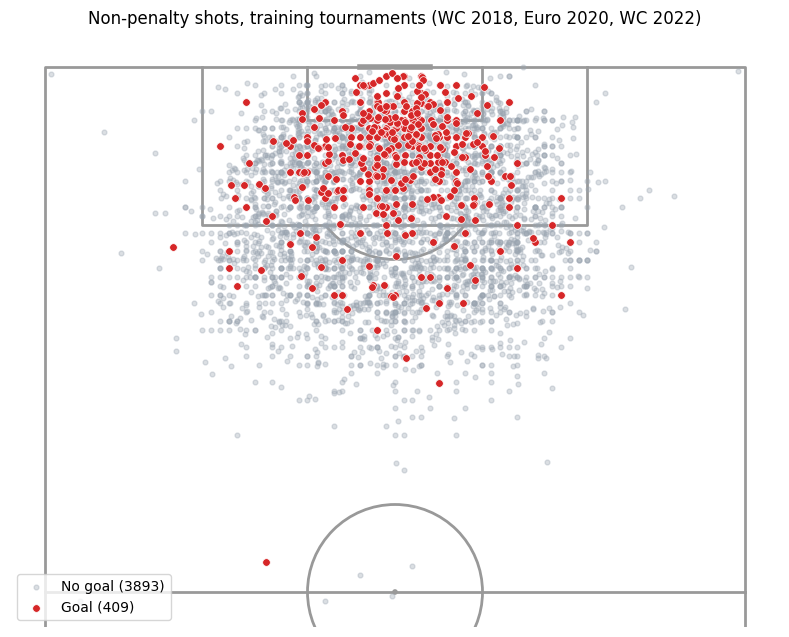

In [ ]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True,
                      pitch_color="white", line_color="#999999")
fig, ax = pitch.draw(figsize=(8, 7))

misses = eda[eda["goal"] == 0]
goals  = eda[eda["goal"] == 1]

pitch.scatter(misses["x"], misses["y"], s=12, color="#9aa5b1", alpha=0.35,
              ax=ax, label=f"No goal ({len(misses)})")
pitch.scatter(goals["x"], goals["y"], s=30, color="#d62728",
              edgecolors="white", linewidth=0.5, ax=ax, label=f"Goal ({len(goals)})")

ax.legend(loc="lower left")
ax.set_title("Non-penalty shots, training tournaments (WC 2018, Euro 2020, WC 2022)")
fig.savefig(FIG_DIR / "eda_shot_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
def rate_table(column):
    """Shots, goals and scoring rate for each value of a column."""
    return (eda.groupby(column)["goal"]
               .agg(shots="size", goals="sum", scoring_rate="mean")
               .sort_values("shots", ascending=False)
               .round(3))

In [ ]:
for column in ["body_part", "technique", "shot_type"]:
    display(rate_table(column))

,shots,goals,scoring_rate
body_part,,,
Right Foot,2189,186,0.085
Left Foot,1299,132,0.102
Head,783,87,0.111
Other,31,4,0.129


,shots,goals,scoring_rate
technique,,,
Normal,3396,312,0.092
Half Volley,516,48,0.093
Volley,285,31,0.109
Diving Header,34,4,0.118
Lob,30,12,0.400
Overhead Kick,24,0,0.000
Backheel,17,2,0.118


,shots,goals,scoring_rate
shot_type,,,
Open Play,4131,400,0.097
Free Kick,169,9,0.053
Corner,2,0,0.000


In [ ]:
eda.groupby("body_part")["x"].median().round(1)

,x
body_part,
Head,112.0
Left Foot,103.0
Other,113.0
Right Foot,102.5


In [ ]:
for column in ["under_pressure", "first_time", "one_on_one", "play_pattern"]:
    display(rate_table(column))

display(eda.groupby("period")["goal"].agg(shots="size", scoring_rate="mean").round(3))

,shots,goals,scoring_rate
under_pressure,,,
False,3430,343,0.100
True,872,66,0.076


,shots,goals,scoring_rate
first_time,,,
False,3083,244,0.079
True,1219,165,0.135


,shots,goals,scoring_rate
one_on_one,,,
False,4125,364,0.088
True,177,45,0.254


,shots,goals,scoring_rate
play_pattern,,,
Regular Play,1511,148,0.098
From Free Kick,828,73,0.088
From Throw In,785,71,0.090
From Corner,710,55,0.077
From Goal Kick,173,17,0.098
From Counter,172,28,0.163
From Keeper,65,11,0.169
From Kick Off,46,4,0.087
Other,12,2,0.167


,shots,scoring_rate
period,,
1,1849,0.077
2,2281,0.111
3,80,0.088
4,92,0.065


### EDA findings (training data, 4,302 shots, 9.5% scored)
1. Goals cluster centrally inside the penalty box; long-range shots rarely score.
2. Headers appear to score more often than foot shots, but they are taken
   closer to goal — distance confounds the raw comparison. A model must
   consider location and shot type together.
3. One-on-ones (25%), counter-attacks (16%) and first-time shots (13.5%) score
   more often; shots under pressure score less often (7.6% vs 10%).
4. Direct free kicks score less often (5.3%) than open-play shots (9.7%).
5. Some categories (lobs, overhead kicks, corners) have very few shots, so their
   rates are unreliable.
6. Scoring is higher in the second half; match period is noted but not used as
   a shot-quality feature.

## 5. Training and Test Split

### Final test set
Euro 2024 is reserved for evaluating the core model on a later tournament.
Its shots are excluded from model fitting and hyperparameter tuning.

Initial data-quality checks included descriptive Euro 2024 outcomes.
The core model was fixed before its performance evaluation. The later
freeze-frame extension was informed by test-set error analysis and is
reported separately as exploratory.

In [ ]:
train = shots[shots["role"] == "train"].reset_index(drop=True)
test  = shots[shots["role"] == "test"].reset_index(drop=True)

print(f"Training: {len(train)} shots | {train['match_id'].nunique()} matches | "
      f"scoring rate {train['goal'].mean():.1%}")
print(f"Test:     {len(test)} shots | {test['match_id'].nunique()} matches | "
      f"scoring rate {test['goal'].mean():.1%}")

overlap = set(train["match_id"]) & set(test["match_id"])
print("\nMatches in both sets:", len(overlap))
print("Latest training match:", train["match_date"].max().date())
print("Earliest test match:  ", test["match_date"].min().date())

Training: 4302 shots | 179 matches | scoring rate 9.5%
Test:     1304 shots | 51 matches | scoring rate 7.5%

Matches in both sets: 0
Latest training match: 2022-12-18
Earliest test match:   2024-06-14


In [ ]:
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)
groups = train["match_id"]

fold_rows = []
for fold, (train_idx, val_idx) in enumerate(cv.split(train, train["goal"], groups=groups), start=1):
    fold_train, fold_val = train.iloc[train_idx], train.iloc[val_idx]
    fold_rows.append({
        "fold":           fold,
        "train_matches":  fold_train["match_id"].nunique(),
        "val_matches":    fold_val["match_id"].nunique(),
        "val_shots":      len(fold_val),
        "val_goals":      int(fold_val["goal"].sum()),
        "val_rate":       round(fold_val["goal"].mean(), 3),
        "shared_matches": len(set(fold_train["match_id"]) & set(fold_val["match_id"])),
    })

pd.DataFrame(fold_rows)

,fold,train_matches,val_matches,val_shots,val_goals,val_rate,shared_matches
0,1,144,35,853,95,0.111,0
1,2,143,36,863,81,0.094,0
2,3,143,36,862,81,0.094,0
3,4,143,36,863,72,0.083,0
4,5,143,36,861,80,0.093,0


### Validation plan

- Use five-fold GroupKFold validation on the training tournaments,
  grouping shots by match ID.
- No match appears in both the training and validation portions of a fold.
- Each validation fold contains 853–863 shots from 35–36 matches.
  Validation scoring rates range from approximately 8.3% to 11.1%.
- Reuse the same folds for the main model comparisons.
- Fit preprocessing separately within each fold using a pipeline.
- These folds mix the earlier tournaments; they are not chronological splits.
- Euro 2024 provides a later-tournament evaluation. It is excluded from
  model fitting and tuning, although descriptive outcomes were inspected
  during initial quality checks.

## 6. Feature Engineering and Preprocessing

### 6.1–6.2 Shot geometry

- **Distance:** straight-line distance from the shot to the goal centre
  at (120, 40), measured in standardised pitch-coordinate units.
  These are not measured physical distances for each stadium.
- **Angle:** the opening between the two goalposts as seen from the shot,
  measured in degrees.
- Goalposts are represented at (120, 36) and (120, 44).
- Larger angles mean a wider geometric opening to the goal; this does
  not account for obstruction by players.
- For geometry calculations, x values above 120 are capped at 120.
  This is a processing convention for the unusual corner location.

In [ ]:
GOAL_X, GOAL_Y, POST_HALF_WIDTH = 120, 40, 4

def add_geometry(df):
    """Add distance in standardised pitch units and angle in degrees."""
    df = df.copy()

    # Treat locations beyond the goal line as on the goal line.
    dx = (GOAL_X - df["x"]).clip(lower=0)
    dy = (df["y"] - GOAL_Y).abs()

    df["distance"] = np.sqrt(dx**2 + dy**2)

    angle = np.arctan2(
        2 * POST_HALF_WIDTH * dx,
        dx**2 + dy**2 - POST_HALF_WIDTH**2
    )

    df["angle"] = np.degrees(
        np.where(angle < 0, angle + np.pi, angle)
    )

    return df

train = add_geometry(train)
test = add_geometry(test)

check = add_geometry(pd.DataFrame({
    "x": [108, 114, 108, 102, 119, 120.1],
    "y": [40, 40, 20, 40, 40, 0.8],
}))

check["description"] = [
    "Central, 12 pitch units from goal",
    "Central, 6 pitch units from goal",
    "Wide shot at x = 108",
    "Central, 18 pitch units from goal",
    "Central, 1 pitch unit from goal",
    "Unusual corner location",
]

check.round(1)

,x,y,distance,angle,description
0,108.0,40.0,12.0,36.9,"Central, 12 pitch units from goal"
1,114.0,40.0,6.0,67.4,"Central, 6 pitch units from goal"
2,108.0,20.0,23.3,10.3,Wide shot at x = 108
3,102.0,40.0,18.0,25.1,"Central, 18 pitch units from goal"
4,119.0,40.0,1.0,151.9,"Central, 1 pitch unit from goal"
5,120.1,0.8,39.2,0.0,Unusual corner location


In [ ]:
print(train[["distance", "angle"]].describe().round(1))

display(train.groupby(pd.cut(train["distance"], [0, 6, 12, 18, 24, 30, 200]), observed=True)["goal"]
             .agg(shots="size", scoring_rate="mean").round(3))
display(train.groupby(pd.cut(train["angle"], [0, 10, 20, 30, 45, 60, 180]), observed=True)["goal"]
             .agg(shots="size", scoring_rate="mean").round(3))

       distance   angle
count    4302.0  4302.0
mean       18.7    25.9
std         8.4    16.8
min         0.8     0.0
25%        12.0    15.2
50%        18.3    19.9
75%        25.0    31.5
max        70.8   160.0


,shots,scoring_rate
distance,,
"(0, 6]",150,0.400
"(6, 12]",936,0.174
"(12, 18]",1026,0.105
"(18, 24]",939,0.043
"(24, 30]",845,0.037
"(30, 200]",406,0.017


,shots,scoring_rate
angle,,
"(0, 10]",106,0.038
"(10, 20]",2068,0.035
"(20, 30]",986,0.101
"(30, 45]",631,0.157
"(45, 60]",321,0.184
"(60, 180]",189,0.397


In [ ]:
def add_context(df):
    """Turn shot context into model-ready 0/1 columns."""
    df = df.copy()
    for col in ["under_pressure", "first_time", "one_on_one"]:
        df[col] = df[col].astype(int)
    df["is_header"]      = (df["body_part"] == "Head").astype(int)
    df["is_free_kick"]   = (df["shot_type"] == "Free Kick").astype(int)
    df["from_counter"]   = (df["play_pattern"] == "From Counter").astype(int)
    df["from_set_piece"] = df["play_pattern"].isin(
        ["From Corner", "From Free Kick", "From Throw In"]).astype(int)
    return df

train = add_context(train)
test  = add_context(test)

NUMERIC_FEATURES     = ["distance", "angle"]
BINARY_FEATURES      = ["is_header", "under_pressure", "first_time", "one_on_one",
                        "is_free_kick", "from_counter", "from_set_piece"]
CATEGORICAL_FEATURES = ["technique"]
BASIC_FEATURES = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES

train[BASIC_FEATURES].head()

,distance,angle,is_header,under_pressure,first_time,one_on_one,is_free_kick,from_counter,from_set_piece,technique
0,25.495098,12.107100,0,0,0,0,0,0,1,Normal
1,15.000000,19.008707,0,0,1,0,0,0,0,Normal
2,19.104973,16.593755,0,0,0,0,0,0,0,Normal
3,16.643317,23.225080,0,0,0,0,0,0,1,Normal
4,10.630146,33.416581,1,0,0,1,0,0,1,Normal


In [ ]:
FORBIDDEN = [
    "outcome", "goal", "statsbomb_xg", "freeze_frame",     # answer, benchmark, Section 8 only
    "match_id", "event_id", "team", "player",              # identifiers, not shot quality
    "tournament", "role", "match_date",
]
leaks = set(BASIC_FEATURES) & set(FORBIDDEN)
assert not leaks, f"Leakage! Remove: {leaks}"
print("Leakage check passed. Features used:", BASIC_FEATURES)

Leakage check passed. Features used: ['distance', 'angle', 'is_header', 'under_pressure', 'first_time', 'one_on_one', 'is_free_kick', 'from_counter', 'from_set_piece', 'technique']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ("numeric",     StandardScaler(), NUMERIC_FEATURES),
    ("binary",      "passthrough",    BINARY_FEATURES),
    ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=30, sparse_output=False),
                    CATEGORICAL_FEATURES),
])

# Demonstration only: fit on TRAINING data and inspect the result
X_demo = preprocessor.fit_transform(train[BASIC_FEATURES])
print("Shape after preprocessing:", X_demo.shape)
pd.DataFrame(X_demo, columns=preprocessor.get_feature_names_out()).describe().round(2).T

Shape after preprocessing: (4302, 15)


,count,mean,std,min,25%,50%,75%,max
numeric__distance,4302.0,0.00,1.00,-2.14,-0.81,-0.06,0.75,6.21
numeric__angle,4302.0,0.00,1.00,-1.54,-0.64,-0.36,0.34,7.98
binary__is_header,4302.0,0.18,0.39,0.00,0.00,0.00,0.00,1.00
binary__under_pressure,4302.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
binary__first_time,4302.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
binary__one_on_one,4302.0,0.04,0.20,0.00,0.00,0.00,0.00,1.00
binary__is_free_kick,4302.0,0.04,0.19,0.00,0.00,0.00,0.00,1.00
binary__from_counter,4302.0,0.04,0.20,0.00,0.00,0.00,0.00,1.00
binary__from_set_piece,4302.0,0.54,0.50,0.00,0.00,1.00,1.00,1.00
categorical__technique_Diving Header,4302.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00


### Feature summary

- Numeric features: distance and angle, standardised inside each
  model's training pipeline.
- Core binary features: header, recorded pressure, first-time contact,
  direct free kick, counterattack and set-piece possession origin.
- `from_set_piece` means the possession originated from a corner,
  free kick or throw-in. It does not necessarily mean the shot followed
  the restart immediately.
- Provisional features: one-on-one and technique. These are used only
  in a sensitivity experiment, not the main core model.
- Technique is one-hot encoded; categories with fewer than 30 examples
  in the relevant training portion are grouped as infrequent.
- Outcome and goal are excluded from predictors. Goal is the target.
- StatsBomb xG is reserved for reference comparison.
- Team, player, match and tournament identifiers are excluded from predictors.
- The preprocessing demonstration above uses the training dataset only.
  Model evaluation fits fresh preprocessing inside each validation fold.
- The forbidden-column assertion checks explicit column names;
  it does not prove that every possible source of leakage has been excluded.

## 7. Model Training and Validation

### 7.0 Model-selection rules and disclosure

**Metrics**
- Primary: log loss.
- Secondary: Brier score, ROC-AUC and variation across folds.
- Calibration is assessed using out-of-fold training predictions before
  the core model's Euro 2024 performance evaluation.

**Practical simplicity rule**
- Compare models using paired differences in log loss across the same folds.
- Calculate the standard deviation of the five differences divided by √5.
- Treat an absolute mean difference smaller than this value as a practical tie.
- Prefer the simpler model when performance is practically tied.
- This is a selection heuristic, not a formal significance test:
  cross-validation folds share training observations.

**Eligible main-model features**
- Distance, angle, header, recorded pressure, first-time contact,
  direct free kick, counterattack and set-piece possession origin.

**Sensitivity features**
- One-on-one and technique are treated as provisional because their
  suitability for the stated prediction timing requires further verification.
- They are excluded from the main candidate models regardless of whether
  they improve the sensitivity experiment's score.

**Disclosure**
- Some exploratory model results were inspected before these rules were
  recorded; the analysis was not fully pre-registered.
- Euro 2024 is excluded from model fitting and tuning, although descriptive
  outcomes were inspected during initial quality checks.
- Gradient-boosting scores on the tuning folds are model-selection scores.
  Nested cross-validation provides an additional assessment of the tuning
  procedure using held-out outer folds.

In [ ]:
GEOMETRY_FEATURES       = ["distance", "angle"]
CORE_BINARY             = ["is_header", "under_pressure", "first_time",
                           "is_free_kick", "from_counter", "from_set_piece"]
PROVISIONAL_BINARY      = ["one_on_one"]
PROVISIONAL_CATEGORICAL = ["technique"]

FEATURE_SETS = {
    "geometry":  {"numeric": GEOMETRY_FEATURES, "binary": [], "categorical": []},
    "core":      {"numeric": GEOMETRY_FEATURES, "binary": CORE_BINARY, "categorical": []},
    "core_plus": {"numeric": GEOMETRY_FEATURES,
                  "binary": CORE_BINARY + PROVISIONAL_BINARY,
                  "categorical": PROVISIONAL_CATEGORICAL},
}

for name, fs in FEATURE_SETS.items():
    print(f"{name:10s}", fs["numeric"] + fs["binary"] + fs["categorical"])

geometry   ['distance', 'angle']
core       ['distance', 'angle', 'is_header', 'under_pressure', 'first_time', 'is_free_kick', 'from_counter', 'from_set_piece']
core_plus  ['distance', 'angle', 'is_header', 'under_pressure', 'first_time', 'is_free_kick', 'from_counter', 'from_set_piece', 'one_on_one', 'technique']


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

X_train = train
y_train = train["goal"]
groups  = train["match_id"]

def make_preprocessor(feature_set):
    """Preprocessing for one feature set; fitted inside each fold by the pipeline."""
    steps = [("numeric", StandardScaler(), feature_set["numeric"])]
    if feature_set["binary"]:
        steps.append(("binary", "passthrough", feature_set["binary"]))
    if feature_set["categorical"]:
        steps.append(("categorical",
                      OneHotEncoder(drop=["Normal"],                    # reference level
                                    handle_unknown="infrequent_if_exist",
                                    min_frequency=30, sparse_output=False),
                      feature_set["categorical"]))
    return ColumnTransformer(steps)

SCORING = {"log_loss": "neg_log_loss", "brier": "neg_brier_score", "roc_auc": "roc_auc"}
fold_scores = {}

def evaluate(name, model):
    """Run 5-fold grouped CV and keep the score for every fold."""
    s = cross_validate(model, X_train, y_train, groups=groups, cv=cv, scoring=SCORING)
    fold_scores[name] = pd.DataFrame({
        "fold":     range(1, 6),
        "log_loss": -s["test_log_loss"],
        "brier":    -s["test_brier"],
        "roc_auc":   s["test_roc_auc"],
    })
    return fold_scores[name].round(4)

def summarise():
    """Mean and spread of each metric for every model evaluated so far."""
    rows = {}
    for name, df in fold_scores.items():
        rows[name] = {
            "log_loss": df["log_loss"].mean(), "log_loss_sd": df["log_loss"].std(),
            "brier":    df["brier"].mean(),    "brier_sd":    df["brier"].std(),
            "roc_auc":  df["roc_auc"].mean(),  "roc_auc_sd":  df["roc_auc"].std(),
        }
    return pd.DataFrame(rows).T.round(4)

# Check the reference level works
check_prep = make_preprocessor(FEATURE_SETS["core_plus"]).fit(X_train)
list(check_prep.get_feature_names_out())

['numeric__distance',
 'numeric__angle',
 'binary__is_header',
 'binary__under_pressure',
 'binary__first_time',
 'binary__is_free_kick',
 'binary__from_counter',
 'binary__from_set_piece',
 'binary__one_on_one',
 'categorical__technique_Diving Header',
 'categorical__technique_Half Volley',
 'categorical__technique_Lob',
 'categorical__technique_Volley',
 'categorical__technique_infrequent_sklearn']

In [ ]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="prior")
evaluate("Baseline (fold training rate)", baseline)

,fold,log_loss,brier,roc_auc
0,1,0.3517,0.0994,0.5
1,2,0.3114,0.0851,0.5
2,3,0.3116,0.0851,0.5
3,4,0.2883,0.0767,0.5
4,5,0.3093,0.0843,0.5


In [ ]:
rates = []
for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train, groups), start=1):
    rates.append({
        "fold": fold,
        "predicted_rate (training part)": y_train.iloc[tr_idx].mean(),
        "actual_rate (validation part)":  y_train.iloc[va_idx].mean(),
    })
pd.DataFrame(rates).round(4)

,fold,predicted_rate (training part),actual_rate (validation part)
0,1,0.0910,0.1114
1,2,0.0954,0.0939
2,3,0.0953,0.0940
3,4,0.0980,0.0834
4,5,0.0956,0.0929


In [ ]:
summarise()

,log_loss,log_loss_sd,brier,brier_sd,roc_auc,roc_auc_sd
Baseline (fold training rate),0.3145,0.023,0.0861,0.0082,0.5,0.0


In [ ]:
from sklearn.linear_model import LogisticRegression

def make_logreg(feature_set_name):
    """Logistic regression pipeline for one feature set."""
    return Pipeline([
        ("prep",  make_preprocessor(FEATURE_SETS[feature_set_name])),
        ("model", LogisticRegression(max_iter=1000)),
    ])

In [ ]:
evaluate("LogReg: geometry", make_logreg("geometry"))

,fold,log_loss,brier,roc_auc
0,1,0.3131,0.0910,0.7461
1,2,0.2853,0.0807,0.7284
2,3,0.2701,0.0746,0.7595
3,4,0.2687,0.0729,0.6943
4,5,0.2624,0.0747,0.7921


In [ ]:
evaluate("LogReg: core", make_logreg("core"))

,fold,log_loss,brier,roc_auc
0,1,0.3092,0.0895,0.7558
1,2,0.2751,0.0785,0.7601
2,3,0.2655,0.0728,0.7684
3,4,0.2603,0.0699,0.7170
4,5,0.2465,0.0698,0.8237


In [ ]:
evaluate("LogReg: core_plus", make_logreg("core_plus"))

,fold,log_loss,brier,roc_auc
0,1,0.3028,0.0879,0.7713
1,2,0.2725,0.0775,0.7635
2,3,0.2649,0.0731,0.7709
3,4,0.2630,0.0706,0.7145
4,5,0.2448,0.0691,0.8218


In [ ]:
summarise()

,log_loss,log_loss_sd,brier,brier_sd,roc_auc,roc_auc_sd
Baseline (fold training rate),0.3145,0.0230,0.0861,0.0082,0.5000,0.0000
LogReg: geometry,0.2799,0.0204,0.0788,0.0075,0.7441,0.0363
LogReg: core,0.2713,0.0235,0.0761,0.0083,0.7650,0.0383
LogReg: core_plus,0.2696,0.0211,0.0756,0.0076,0.7684,0.0381


In [ ]:
def paired_comparison(model_a, model_b, metric="log_loss"):
    """Per-fold difference (B − A). For log loss and Brier, negative = B is better."""
    diff = fold_scores[model_b][metric] - fold_scores[model_a][metric]
    se = diff.std() / np.sqrt(len(diff))
    better = (diff < 0).sum() if metric in ("log_loss", "brier") else (diff > 0).sum()
    return pd.Series({
        "mean_difference": diff.mean(),
        "standard_error":  se,
        "difference_in_SEs": diff.mean() / se,
        "folds_where_B_better": f"{better}/5",
        "tied (|mean| < 1 SE)": abs(diff.mean()) < se,
    })

pd.DataFrame({
    "geometry → core":   paired_comparison("LogReg: geometry", "LogReg: core"),
    "core → core_plus":  paired_comparison("LogReg: core", "LogReg: core_plus"),
}).T

,mean_difference,standard_error,difference_in_SEs,folds_where_B_better,tied (|mean| < 1 SE)
geometry → core,-0.008578,0.002158,-3.974385,5/5,False
core → core_plus,-0.001724,0.001471,-1.171605,4/5,False


### 7.3–7.4 Logistic-regression results

| Model | Log loss | Brier | ROC-AUC |
|---|---:|---:|---:|
| Fold training-rate baseline | 0.3145 | 0.0861 | 0.500 |
| Geometry logistic regression | 0.2799 | 0.0788 | 0.744 |
| Core logistic regression | 0.2713 | 0.0761 | 0.765 |
| Core plus provisional features | 0.2696 | 0.0756 | 0.768 |

Geometry improves predictions over the constant baseline.

Adding core context features improves log loss in all five validation
folds, with a mean reduction of approximately 0.0086.

The provisional-feature model gives a further small average reduction
of approximately 0.0017 and improves four of five folds.

However, provisional features are excluded from the eligible main models
because their suitability for the prediction timing requires further
verification. This decision is based on feature eligibility, not the
numerical tie rule.

The paired-fold comparisons are descriptive selection aids, not formal
significance tests. Some exploratory results were inspected before the
selection rules were recorded.

In [ ]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

hgb = Pipeline([
    ("prep",  make_preprocessor(FEATURE_SETS["core"])),
    ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
])

param_grid = {
    "model__learning_rate":    [0.03, 0.1],
    "model__max_depth":        [2, 3],
    "model__max_iter":         [100, 300],
    "model__min_samples_leaf": [20, 50],
}

start = time.time()
search = GridSearchCV(hgb, param_grid, scoring="neg_log_loss", cv=cv, n_jobs=-1)
search.fit(X_train, y_train, groups=groups)

print(f"Search time: {time.time() - start:.0f}s")
print("Best settings:", search.best_params_)
print(f"Best selection-score log loss: {-search.best_score_:.4f}")

Search time: 44s
Best settings: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 100, 'model__min_samples_leaf': 50}
Best selection-score log loss: 0.2725


In [ ]:
res = pd.DataFrame(search.cv_results_)
grid_table = pd.DataFrame({
    "learning_rate":    res["param_model__learning_rate"],
    "max_depth":        res["param_model__max_depth"],
    "max_iter":         res["param_model__max_iter"],
    "min_samples_leaf": res["param_model__min_samples_leaf"],
    "cv_log_loss":     -res["mean_test_score"],
    "sd":               res["std_test_score"],
    "rank":             res["rank_test_score"],
}).sort_values("rank")
grid_table.round(4)

,learning_rate,max_depth,max_iter,min_samples_leaf,cv_log_loss,sd,rank
5,0.03,3,100,50,0.2725,0.0223,1
4,0.03,3,100,20,0.2726,0.0217,2
1,0.03,2,100,50,0.2730,0.0209,3
0,0.03,2,100,20,0.2731,0.0208,4
3,0.03,2,300,50,0.2732,0.0232,5
2,0.03,2,300,20,0.2732,0.0223,6
9,0.10,2,100,50,0.2735,0.0233,7
8,0.10,2,100,20,0.2736,0.0229,8
6,0.03,3,300,20,0.2767,0.0240,9
12,0.10,3,100,20,0.2773,0.0244,10


In [ ]:
evaluate("GBoost: core (tuned — selection score)", search.best_estimator_)
summarise()

,log_loss,log_loss_sd,brier,brier_sd,roc_auc,roc_auc_sd
Baseline (fold training rate),0.3145,0.0230,0.0861,0.0082,0.5000,0.0000
LogReg: geometry,0.2799,0.0204,0.0788,0.0075,0.7441,0.0363
LogReg: core,0.2713,0.0235,0.0761,0.0083,0.7650,0.0383
LogReg: core_plus,0.2696,0.0211,0.0756,0.0076,0.7684,0.0381
GBoost: core (tuned — selection score),0.2725,0.0249,0.0764,0.0085,0.7586,0.0470


In [ ]:
from sklearn.model_selection import cross_val_score

inner_search = GridSearchCV(hgb, param_grid, scoring="neg_log_loss",
                            cv=GroupKFold(n_splits=4), n_jobs=-1)
nested_scores = cross_val_score(inner_search, X_train, y_train, groups=groups,
                                cv=cv, scoring="neg_log_loss",
                                params={"groups": groups})
print("Nested CV log loss:", (-nested_scores).round(4), "| mean:", round(-nested_scores.mean(), 4))

Nested CV log loss: [0.3114 0.2781 0.2619 0.2648 0.2472] | mean: 0.2727


### 7.5 Gradient boosting with core features

The search compared 16 combinations of learning rate, maximum depth,
number of boosting iterations and minimum leaf size.

The selected configuration was:
- learning_rate = 0.03
- max_depth = 3
- max_iter = 100
- min_samples_leaf = 50

| Model | Log loss | Brier | ROC-AUC |
|---|---:|---:|---:|
| Core logistic regression | 0.2713 | 0.0761 | 0.7650 |
| Core gradient boosting: selection score | 0.2725 | 0.0764 | 0.7586 |
| Core gradient boosting: nested CV | 0.2727 | Not calculated | Not calculated |

The more flexible configurations generally performed worse in this search.
This is consistent with overfitting, but validation scores alone do not
establish the precise cause.

The selection score uses the folds that selected the settings.
Nested cross-validation repeats tuning inside each outer training fold.

The nested and non-nested log-loss estimates were similar.
Their difference is not a precise estimate of tuning optimism.

Core logistic regression had slightly better average scores.
The paired comparison below determines how this difference is treated
under the practical simplicity rule.

In [ ]:
CANDIDATES = ["LogReg: geometry", "LogReg: core", "GBoost: core (tuned — selection score)"]

summary = summarise()
candidates = summary.loc[CANDIDATES].sort_values("log_loss")
best = candidates.index[0]
print("Lowest log loss:", best)
candidates

Lowest log loss: LogReg: core


,log_loss,log_loss_sd,brier,brier_sd,roc_auc,roc_auc_sd
LogReg: core,0.2713,0.0235,0.0761,0.0083,0.7650,0.0383
GBoost: core (tuned — selection score),0.2725,0.0249,0.0764,0.0085,0.7586,0.0470
LogReg: geometry,0.2799,0.0204,0.0788,0.0075,0.7441,0.0363


In [ ]:
comparison = pd.DataFrame({
    f"{best} → {m}": paired_comparison(best, m, "log_loss")
    for m in CANDIDATES if m != best
}).T
comparison

,mean_difference,standard_error,difference_in_SEs,folds_where_B_better,tied (|mean| < 1 SE)
LogReg: core → LogReg: geometry,0.008578,0.002158,3.974385,0/5,False
LogReg: core → GBoost: core (tuned — selection score),0.001151,0.00175,0.657828,1/5,True


In [ ]:
brier_check = pd.DataFrame({
    f"{best} → {m}": paired_comparison(best, m, "brier")
    for m in CANDIDATES if m != best
}).T
brier_check

,mean_difference,standard_error,difference_in_SEs,folds_where_B_better,tied (|mean| < 1 SE)
LogReg: core → LogReg: geometry,0.002665,0.0006,4.438513,0/5,False
LogReg: core → GBoost: core (tuned — selection score),0.000296,0.000288,1.027246,2/5,False


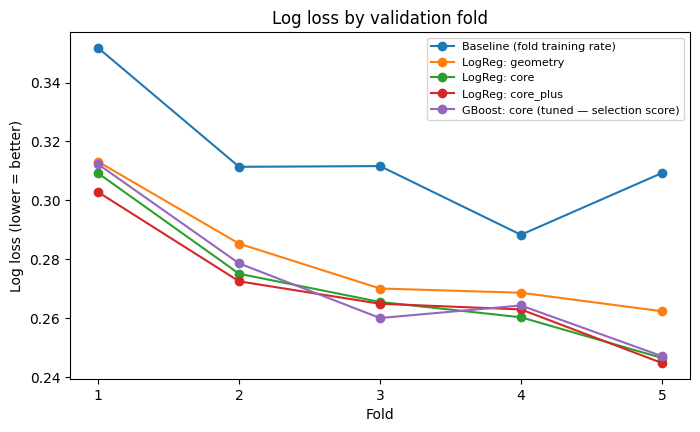

In [ ]:
plot_models = ["Baseline (fold training rate)", "LogReg: geometry", "LogReg: core",
               "LogReg: core_plus", "GBoost: core (tuned — selection score)"]

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in plot_models:
    ax.plot(fold_scores[name]["fold"], fold_scores[name]["log_loss"], marker="o", label=name)
ax.set(xlabel="Fold", ylabel="Log loss (lower = better)", xticks=range(1, 6),
       title="Log loss by validation fold")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "fold_log_loss.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.6 Model choice

Eligible main candidates are geometry logistic regression, core logistic
regression and core gradient boosting. The provisional-feature model is
reported separately as a sensitivity experiment.

| Model | Mean log loss | Brier | ROC-AUC |
|---|---:|---:|---:|
| Core logistic regression | 0.2713 | 0.0761 | 0.7650 |
| Core gradient boosting: selection score | 0.2725 | 0.0764 | 0.7586 |
| Geometry logistic regression | 0.2799 | 0.0788 | 0.7441 |

Core logistic regression improved log loss over geometry logistic
regression in all five folds.

The mean log-loss difference between boosting and core logistic regression
was approximately 0.0012, smaller than the paired-fold heuristic threshold
of approximately 0.0018.

Under the practical simplicity rule, these models are treated as tied.
Core logistic regression is selected because it is simpler to interpret
and has the lower average log loss.

**Chosen main model:** logistic regression with core features.

These comparisons support this choice within the models and validation
scheme tested. They do not establish that logistic regression is always
better than gradient boosting.

Calibration is checked using training out-of-fold predictions before
evaluating the fixed core model on Euro 2024.

In [ ]:
final_model = make_logreg("core").fit(X_train, y_train)

prep = final_model.named_steps["prep"]
logit = final_model.named_steps["model"]

names = [
    name.split("__", 1)[1]
    for name in prep.get_feature_names_out()
]

coefs = pd.Series(logit.coef_[0], index=names)

scaler = prep.named_transformers_["numeric"]
feature_sd = pd.Series(
    scaler.scale_,
    index=GEOMETRY_FEATURES
)

UNITS = {
    "distance": (5, "pitch units"),
    "angle": (10, "degrees"),
}

rows = []

for feature in names:
    if feature in UNITS:
        step, unit = UNITS[feature]
        coefficient = coefs[feature] / feature_sd[feature] * step
        change = f"+{step} {unit}"
    else:
        coefficient = coefs[feature]
        change = "0 → 1"

    odds_ratio = np.exp(coefficient)
    starting_probability = 0.10

    adjusted_probability = (
        odds_ratio * starting_probability
        / (
            1 - starting_probability
            + odds_ratio * starting_probability
        )
    )

    rows.append({
        "feature": feature,
        "change": change,
        "coefficient": coefficient,
        "odds_ratio": odds_ratio,
        "illustrative_probability_from_10%": adjusted_probability,
    })

odds_table = pd.DataFrame(rows).sort_values("odds_ratio")

print(f"Regularisation: L2, C = {logit.C}")
print(
    f"Distance standard deviation: "
    f"{feature_sd['distance']:.1f} pitch units"
)
print(
    f"Angle standard deviation: "
    f"{feature_sd['angle']:.1f} degrees"
)

odds_table.round(3)

Regularisation: L2, C = 1.0
Distance standard deviation: 8.4 pitch units
Angle standard deviation: 16.8 degrees


,feature,change,coefficient,odds_ratio,illustrative_probability_from_10%
2,is_header,0 → 1,-0.790,0.454,0.048
3,under_pressure,0 → 1,-0.502,0.605,0.063
0,distance,+5 pitch units,-0.473,0.623,0.065
7,from_set_piece,0 → 1,-0.342,0.710,0.073
4,first_time,0 → 1,0.005,1.005,0.100
1,angle,+10 degrees,0.253,1.288,0.125
6,from_counter,0 → 1,0.360,1.433,0.137
5,is_free_kick,0 → 1,0.733,2.082,0.188


In [ ]:
CORE_FEATURES = GEOMETRY_FEATURES + CORE_BINARY
X_train[CORE_FEATURES].corr().round(2)

,distance,angle,is_header,under_pressure,first_time,is_free_kick,from_counter,from_set_piece
distance,1.00,-0.75,-0.50,-0.20,-0.14,0.24,-0.03,-0.07
angle,-0.75,1.00,0.49,0.18,0.08,-0.14,-0.01,0.12
is_header,-0.50,0.49,1.00,0.35,-0.30,-0.10,-0.08,0.23
under_pressure,-0.20,0.18,0.35,1.00,-0.15,-0.10,-0.01,0.05
first_time,-0.14,0.08,-0.30,-0.15,1.00,-0.13,0.00,-0.03
is_free_kick,0.24,-0.14,-0.10,-0.10,-0.13,1.00,-0.04,0.19
from_counter,-0.03,-0.01,-0.08,-0.01,0.00,-0.04,1.00,-0.22
from_set_piece,-0.07,0.12,0.23,0.05,-0.03,0.19,-0.22,1.00


### 7.7 Interpretation of the core logistic regression

The model is fitted on all 4,302 training shots.
The table above reports odds ratios after accounting for numeric scaling.

- A five-pitch-unit increase in distance is associated with lower scoring odds.
- A ten-degree increase in goal opening angle is associated with higher odds.
- Headers and recorded pressure have negative conditional associations.
- First-time contact has little additional association in this fitted model.
- Counterattacks and direct free kicks have positive conditional associations.

These coefficients describe associations while holding the other inputs fixed.
They do not show what would happen if a player deliberately changed one factor.

The raw header scoring rate is higher than the right-foot scoring rate,
but headers occur closer to goal. The adjusted model gives headers lower
odds than non-headers with the same recorded inputs.

This illustrates why raw comparisons and adjusted comparisons can differ.
It does not prove that the model has removed every source of confounding.

Distance and angle are strongly correlated. Interpret their combined
relationship with scoring rather than treating either coefficient as a
complete measure of location importance.

The direct-free-kick coefficient is conditional on the other inputs,
including possession origin. It should not be interpreted as advice to
prefer free kicks or as proof of a particular football mechanism.

The illustrative probability column starts from 10% and changes one input.
Some combinations may be uncommon or physically unrealistic.

L2 regularisation shrinks coefficients. No coefficient uncertainty
intervals are estimated here.

## 8. Exploratory Freeze-Frame Extension

This extension was developed after inspecting the core model's Euro 2024
errors. Its position in the notebook groups feature development together;
it does not represent the chronological order of the work.

Training and cross-validation use the earlier tournaments only.
However, feature development was informed by the held-out results,
so the subsequent Euro 2024 comparison is exploratory.

### Features

| Feature | Meaning |
|---|---|
| gk_dist_to_goal | Recorded goalkeeper distance from the goal centre |
| gk_in_triangle | Whether the recorded goalkeeper lies inside the shooting triangle |
| defenders_in_triangle | Number of visible outfield opponents inside that triangle |
| nearest_defender_dist | Distance to the nearest visible outfield opponent |

Goalkeeper distance from the goal centre combines sideways displacement
and distance from the goal line. It is not a direct measure of how far
the goalkeeper has moved off the line.

A player outside the shooting triangle is not automatically badly positioned.

Freeze frames record visible players, not necessarily every player.
Defender counts and nearest-defender distances therefore describe the
recorded players.

Both models are compared on the same training shots with complete
freeze-frame features.

The same practical one-SE comparison is reported as a heuristic,
not a formal significance test.

In [ ]:
def in_triangle(px, py, sx, sy):
    """Check membership of a non-degenerate shooting triangle."""

    def side(ax, ay, bx, by, cx, cy):
        return (
            (ax - cx) * (by - cy)
            - (bx - cx) * (ay - cy)
        )

    # Triangle vertices: shot and the two goalposts.
    area_twice = abs(side(sx, sy, 120, 36, 120, 44))
    tolerance = 1e-9

    # A shot on the goal line creates a zero-area triangle.
    # Convention: count no players inside this degenerate region.
    if area_twice <= tolerance:
        return False

    d1 = side(px, py, sx, sy, 120, 36)
    d2 = side(px, py, 120, 36, 120, 44)
    d3 = side(px, py, 120, 44, sx, sy)

    has_negative = min(d1, d2, d3) < -tolerance
    has_positive = max(d1, d2, d3) > tolerance

    return not (has_negative and has_positive)


# Small geometry checks.
assert in_triangle(115, 40, 108, 40)
assert not in_triangle(115, 60, 108, 40)
assert not in_triangle(120, 70, 120, 0.8)


def freeze_frame_features(row):
    """Calculate geometry from recorded opposing-player positions."""
    sx = min(row["x"], 120)
    sy = row["y"]
    frame = row["freeze_frame"]

    if not isinstance(frame, list) or not frame:
        return pd.Series({
            "gk_dist_to_goal": np.nan,
            "gk_in_triangle": np.nan,
            "defenders_in_triangle": np.nan,
            "nearest_defender_dist": np.nan,
        })

    opponents = [
        player for player in frame
        if not player["teammate"]
    ]

    keepers = [
        player for player in opponents
        if player["position"]["name"] == "Goalkeeper"
    ]

    outfield = [
        player for player in opponents
        if player["position"]["name"] != "Goalkeeper"
    ]

    features = {
        "defenders_in_triangle": sum(
            in_triangle(*player["location"], sx, sy)
            for player in outfield
        )
    }

    distances = [
        np.hypot(
            player["location"][0] - sx,
            player["location"][1] - sy
        )
        for player in outfield
    ]

    features["nearest_defender_dist"] = (
        min(distances) if distances else np.nan
    )

    if len(keepers) == 1:
        gx, gy = keepers[0]["location"]

        features["gk_dist_to_goal"] = np.hypot(
            GOAL_X - gx,
            GOAL_Y - gy
        )
        features["gk_in_triangle"] = int(
            in_triangle(gx, gy, sx, sy)
        )
    else:
        features["gk_dist_to_goal"] = np.nan
        features["gk_in_triangle"] = np.nan

    return pd.Series(features)


FF_FEATURES = [
    "gk_dist_to_goal",
    "gk_in_triangle",
    "defenders_in_triangle",
    "nearest_defender_dist",
]

train = train.drop(
    columns=FF_FEATURES,
    errors="ignore"
).join(train.apply(freeze_frame_features, axis=1))

test = test.drop(
    columns=FF_FEATURES,
    errors="ignore"
).join(test.apply(freeze_frame_features, axis=1))

print("Geometry checks passed.")
train[FF_FEATURES].describe().round(2).T

Geometry checks passed.


,count,mean,std,min,25%,50%,75%,max
gk_dist_to_goal,4301.0,3.07,2.39,0.0,1.92,2.75,3.75,64.76
gk_in_triangle,4301.0,0.96,0.19,0.0,1.00,1.00,1.00,1.00
defenders_in_triangle,4302.0,0.79,0.97,0.0,0.00,1.00,1.00,7.00
nearest_defender_dist,4302.0,3.06,2.33,0.0,1.41,2.33,3.98,32.22


In [ ]:
print("Training shots missing goalkeeper:", train["gk_dist_to_goal"].isna().sum())
print("Test shots missing goalkeeper:    ", test["gk_dist_to_goal"].isna().sum())

ff_train = train.dropna(subset=FF_FEATURES).reset_index(drop=True)
print("Eligible training shots:", len(ff_train), "of", len(train))

Training shots missing goalkeeper: 1
Test shots missing goalkeeper:     0
Eligible training shots: 4301 of 4302


In [ ]:
for col in ["gk_in_triangle", "defenders_in_triangle"]:
    display(ff_train.groupby(ff_train[col].clip(upper=3))["goal"]
                    .agg(shots="size", scoring_rate="mean").round(3))

,shots,scoring_rate
gk_in_triangle,,
0.0,161,0.317
1.0,4140,0.086


,shots,scoring_rate
defenders_in_triangle,,
0.0,2055,0.134
1.0,1481,0.069
2.0,484,0.045
3.0,281,0.036


In [ ]:
ff_train[GEOMETRY_FEATURES + FF_FEATURES].corr().round(2)

,distance,angle,gk_dist_to_goal,gk_in_triangle,defenders_in_triangle,nearest_defender_dist
distance,1.00,-0.75,-0.02,0.16,0.20,0.46
angle,-0.75,1.00,-0.09,-0.16,-0.10,-0.32
gk_dist_to_goal,-0.02,-0.09,1.00,-0.33,-0.19,0.01
gk_in_triangle,0.16,-0.16,-0.33,1.00,0.08,-0.05
defenders_in_triangle,0.20,-0.10,-0.19,0.08,1.00,0.29
nearest_defender_dist,0.46,-0.32,0.01,-0.05,0.29,1.00


### 8.2 Freeze-frame checks

The outputs above describe feature availability, distributions and
training-data associations.

Both comparison models use the same rows with complete required features.
The eligible sample size is reported by the code.

Distances are measured in standardised pitch-coordinate units.

Large recorded goalkeeper distances should be inspected before being
described as genuine tactical events. A large value could reflect the
match situation or a data-quality issue.

The grouped scoring rates are descriptive. They do not establish that
moving the goalkeeper or adding a defender would cause the observed change.

Low correlations with shot location do not, by themselves, prove that
the new variables contain useful predictive information.
The model comparison below evaluates their additional predictive value.

For shots on the goal line, the shooting triangle has zero area.
The implementation treats its player count and goalkeeper indicator as
zero by convention. This edge-case handling should be retained in the
project's limitations.

In [ ]:
FEATURE_SETS["core_ff"] = {
    "numeric":     GEOMETRY_FEATURES + ["gk_dist_to_goal", "nearest_defender_dist",
                                        "defenders_in_triangle"],
    "binary":      CORE_BINARY + ["gk_in_triangle"],
    "categorical": [],
}
print(FEATURE_SETS["core_ff"]["numeric"] + FEATURE_SETS["core_ff"]["binary"])

['distance', 'angle', 'gk_dist_to_goal', 'nearest_defender_dist', 'defenders_in_triangle', 'is_header', 'under_pressure', 'first_time', 'is_free_kick', 'from_counter', 'from_set_piece', 'gk_in_triangle']


In [ ]:
X_ff, y_ff, groups_ff = ff_train, ff_train["goal"], ff_train["match_id"]

ff_fold_scores = {}
for name in ["core", "core_ff"]:
    s = cross_validate(make_logreg(name), X_ff, y_ff, groups=groups_ff, cv=cv, scoring=SCORING)
    ff_fold_scores[name] = pd.DataFrame({
        "fold":     range(1, 6),
        "log_loss": -s["test_log_loss"],
        "brier":    -s["test_brier"],
        "roc_auc":   s["test_roc_auc"],
    })

summary_ff = pd.DataFrame({name: df.drop(columns="fold").mean()
                           for name, df in ff_fold_scores.items()}).T
summary_ff.round(4)

,log_loss,brier,roc_auc
core,0.2708,0.0760,0.7659
core_ff,0.2626,0.0739,0.7855


In [ ]:
rows = {}
for metric in ["log_loss", "brier", "roc_auc"]:
    diff = ff_fold_scores["core_ff"][metric] - ff_fold_scores["core"][metric]
    se = diff.std() / np.sqrt(len(diff))
    better = (diff < 0).sum() if metric != "roc_auc" else (diff > 0).sum()
    rows[metric] = {
        "mean_difference": diff.mean(),
        "standard_error": se,
        "difference_in_SEs": diff.mean() / se,
        "folds_where_ff_better": f"{better}/5",
        "beyond 1 SE": abs(diff.mean()) > se,
    }
pd.DataFrame(rows).T

,mean_difference,standard_error,difference_in_SEs,folds_where_ff_better,beyond 1 SE
log_loss,-0.008185,0.003765,-2.173753,4/5,True
brier,-0.002113,0.000747,-2.826698,5/5,True
roc_auc,0.019628,0.01141,1.720202,4/5,True


### 8.3 Core versus core plus freeze frames

The generated tables above compare both models on exactly the same
eligible training shots and grouped validation folds.

Lower log loss and Brier score indicate better probability predictions.
Higher ROC-AUC indicates better ranking of goals above non-goals.

Paired differences are calculated as:
core plus freeze frames minus core.

Negative differences favour freeze frames for log loss and Brier score.
Positive differences favour freeze frames for ROC-AUC.

The one-SE threshold is a practical comparison heuristic. It is not a
formal significance test because folds share training data.

Any improvement supports additional predictive value from the tested
recorded-position features within this analysis.

It does not establish that these are the most valuable possible missing
features or fully explain the performance difference from StatsBomb.

Feature development was informed by Euro 2024 error inspection, so this
extension remains exploratory.

In [ ]:
ff_model = make_logreg("core_ff").fit(X_ff, y_ff)

prep_ff = ff_model.named_steps["prep"]
logit_ff = ff_model.named_steps["model"]

names_ff = [
    name.split("__", 1)[1]
    for name in prep_ff.get_feature_names_out()
]

coefs_ff = pd.Series(
    logit_ff.coef_[0],
    index=names_ff
)

numeric_ff = FEATURE_SETS["core_ff"]["numeric"]

sd_ff = pd.Series(
    prep_ff.named_transformers_["numeric"].scale_,
    index=numeric_ff
)

UNITS_FF = {
    "distance": (5, "+5 pitch units"),
    "angle": (10, "+10 degrees"),
    "gk_dist_to_goal": (
        5, "+5 pitch units from goal centre"
    ),
    "nearest_defender_dist": (
        1, "+1 pitch unit to nearest visible defender"
    ),
    "defenders_in_triangle": (
        1, "+1 visible defender in shooting triangle"
    ),
}

rows = []

for feature in names_ff:
    if feature in UNITS_FF:
        step, label = UNITS_FF[feature]
        coefficient = (
            coefs_ff[feature] / sd_ff[feature] * step
        )
    else:
        label = "0 → 1"
        coefficient = coefs_ff[feature]

    odds_ratio = np.exp(coefficient)
    probability = (
        odds_ratio * 0.10
        / (0.90 + odds_ratio * 0.10)
    )

    rows.append({
        "feature": feature,
        "change": label,
        "odds_ratio": odds_ratio,
        "illustrative_probability_from_10%": probability,
    })

odds_ff = pd.DataFrame(rows).sort_values("odds_ratio")
odds_ff.round(3)

,feature,change,odds_ratio,illustrative_probability_from_10%
5,is_header,0 → 1,0.543,0.057
0,distance,+5 pitch units,0.639,0.066
4,defenders_in_triangle,+1 visible defender in shooting triangle,0.706,0.073
6,under_pressure,0 → 1,0.727,0.075
10,from_set_piece,0 → 1,0.838,0.085
7,first_time,0 → 1,0.971,0.097
11,gk_in_triangle,0 → 1,0.989,0.099
3,nearest_defender_dist,+1 pitch unit to nearest visible defender,1.140,0.112
9,from_counter,0 → 1,1.174,0.115
1,angle,+10 degrees,1.334,0.129


### 8.4 Interpretation of the freeze-frame model

The generated coefficient table reports associations while holding
the other model inputs fixed.

- Goalkeeper distance measures displacement from the goal centre,
  not simply distance off the goal line.
- Defender counts describe visible outfield opponents within the
  geometric shooting triangle.
- Nearest-defender distance refers to the nearest recorded outfield
  opponent, who may not be the nearest opponent on the pitch.

Changes in core-feature coefficients after adding positions suggest
overlap in the information represented by these inputs.

They do not prove a causal mechanism or show that the original features
were only proxies for defender positioning.

Coefficients depend on model specification, correlation between inputs,
regularisation and the available sample.

Illustrative changes from a 10% starting probability are mathematical
comparisons, not recommendations to alter one football action while
everything else remains unchanged.

The extension was developed after inspecting held-out errors.
Its evaluation is exploratory and requires confirmation on new data.

## 9. Final Evaluation and Error Analysis

### 9.1 Calibration assessment using training predictions

Generate out-of-fold probabilities using the grouped training folds.

The recorded practical rule is to consider recalibration if:
- the estimated calibration slope is outside 0.8–1.2, or
- the mean predicted probability differs from the observed scoring
  rate by more than one percentage point.

These thresholds are project-specific heuristics, not universal standards.

Any calibration model would be fitted using training data only.
The calibration curve is also inspected because aggregate measures
can hide differences within probability ranges.

The following fitted calibration relationship is diagnostic; it does
not change the main model's predictions.

In [ ]:
from sklearn.model_selection import cross_val_predict

oof_pred = cross_val_predict(make_logreg("core"), X_train, y_train,
                             groups=groups, cv=cv, method="predict_proba")[:, 1]

print(f"Mean predicted: {oof_pred.mean():.4f} | Actual scoring rate: {y_train.mean():.4f}")

Mean predicted: 0.0951 | Actual scoring rate: 0.0951


In [ ]:
def calibration_table(y, p, n_bins=10):
    """Compare predicted and observed rates in equal-count bins."""
    y = np.asarray(y)
    p = np.asarray(p)

    bins = pd.qcut(
        p,
        n_bins,
        duplicates="drop"
    )

    return (
        pd.DataFrame({"y": y, "p": p})
        .groupby(bins, observed=True)
        .agg(
            shots=("y", "size"),
            mean_predicted=("p", "mean"),
            actual_rate=("y", "mean"),
        )
        .round(3)
    )


def calibration_slope_intercept(y, p):
    """Estimate a diagnostic calibration slope and intercept."""
    p = np.asarray(p, dtype=float)

    # Avoid infinite log-odds for probabilities exactly 0 or 1.
    p = np.clip(p, 1e-10, 1 - 1e-10)

    logit_p = np.log(p / (1 - p)).reshape(-1, 1)

    diagnostic_fit = LogisticRegression(
        C=1e6,
        max_iter=1000
    ).fit(logit_p, y)

    return (
        round(float(diagnostic_fit.coef_[0][0]), 3),
        round(float(diagnostic_fit.intercept_[0]), 3),
    )


print(
    "Calibration slope, intercept:",
    calibration_slope_intercept(
        y_train.values,
        oof_pred
    )
)

calibration_table(y_train.values, oof_pred)

Calibration slope, intercept: (0.969, -0.061)


,shots,mean_predicted,actual_rate
"(-0.000711, 0.021]",431,0.015,0.021
"(0.021, 0.0305]",430,0.026,0.028
"(0.0305, 0.04]",430,0.035,0.044
"(0.04, 0.05]",430,0.045,0.044
"(0.05, 0.0631]",430,0.056,0.019
"(0.0631, 0.0787]",430,0.070,0.077
"(0.0787, 0.0996]",430,0.089,0.091
"(0.0996, 0.133]",430,0.116,0.121
"(0.133, 0.199]",430,0.161,0.167
"(0.199, 0.965]",431,0.338,0.339


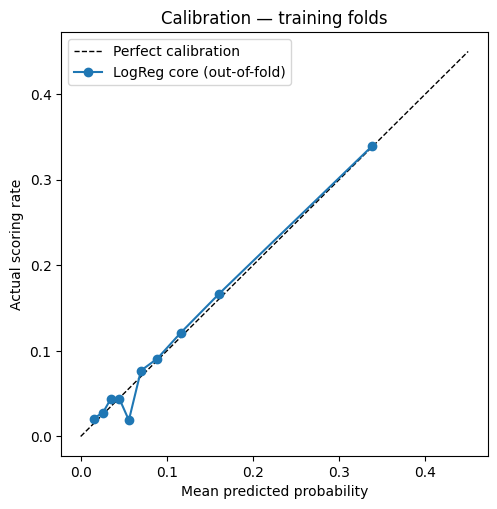

In [ ]:
cal = calibration_table(y_train.values, oof_pred)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 0.45], [0, 0.45], "k--", linewidth=1, label="Perfect calibration")
ax.plot(cal["mean_predicted"], cal["actual_rate"], marker="o", label="LogReg core (out-of-fold)")
ax.set(xlabel="Mean predicted probability", ylabel="Actual scoring rate",
       title="Calibration — training folds")
ax.legend()
fig.savefig(FIG_DIR / "calibration_training.png", dpi=150, bbox_inches="tight")
plt.show()

The saved out-of-fold calibration slope is approximately 0.97,
with an intercept of approximately −0.06.

Mean predicted and observed scoring rates are both approximately 9.51%.
These results fall within the recorded practical thresholds, so the
core model is retained without recalibration.

The binned curve shows local differences that aggregate statistics
do not capture. Overall agreement does not imply perfect calibration
for every shot type or probability range.

### 9.2 Core model evaluation — Euro 2024
Model frozen: logistic regression, core features, fitted on all training shots.
Compared with (a) a baseline predicting the training scoring rate and
(b) StatsBomb's supplied xG as a professional reference.

In [ ]:
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

X_test, y_test = test, test["goal"]
test_pred = final_model.predict_proba(X_test)[:, 1]
train_rate = y_train.mean()

def metrics(y, p):
    return {
        "log_loss":       log_loss(y, p),
        "brier":          brier_score_loss(y, p),
        "roc_auc":        roc_auc_score(y, p) if np.std(p) > 0 else 0.5,
        "mean_predicted": np.mean(p),
        "actual_rate":    np.mean(y),
        "total_xG":       np.sum(p),
        "goals":          np.sum(y),
    }

test_results = pd.DataFrame({
    "Baseline (training rate)":  metrics(y_test, np.full(len(y_test), train_rate)),
    "LogReg core (ours)":        metrics(y_test, test_pred),
    "StatsBomb xG (reference)":  metrics(y_test, test["statsbomb_xg"]),
}).T.round(4)
test_results

,log_loss,brier,roc_auc,mean_predicted,actual_rate,total_xG,goals
Baseline (training rate),0.2692,0.0699,0.5000,0.0951,0.0752,123.9740,98.0
LogReg core (ours),0.2401,0.0651,0.7400,0.0855,0.0752,111.5195,98.0
StatsBomb xG (reference),0.2251,0.0615,0.7867,0.0854,0.0752,111.4120,98.0


In [ ]:
print("Test calibration slope, intercept:", calibration_slope_intercept(y_test.values, test_pred))
calibration_table(y_test.values, test_pred, n_bins=5)

Test calibration slope, intercept: (0.944, -0.269)


,shots,mean_predicted,actual_rate
"(-0.000756, 0.0295]",261,0.019,0.019
"(0.0295, 0.0484]",261,0.039,0.019
"(0.0484, 0.0761]",260,0.061,0.062
"(0.0761, 0.121]",261,0.097,0.084
"(0.121, 0.737]",261,0.212,0.192


### 9.2–9.3 Core model evaluation on Euro 2024

The core model was fixed before its performance evaluation.
Euro 2024 was excluded from fitting and tuning, although descriptive
outcomes were inspected during initial data-quality checks.

| Model | Log loss | Brier | ROC-AUC | Total xG |
|---|---:|---:|---:|---:|
| Training-rate baseline | 0.2692 | 0.0699 | 0.500 | 124.0 |
| Core logistic regression | 0.2401 | 0.0651 | 0.740 | 111.5 |
| StatsBomb xG reference | 0.2251 | 0.0615 | 0.787 | 111.4 |

The evaluation contains 1,304 non-penalty shots and 98 goals.

The core model outperforms the constant baseline on this later tournament.
Its log loss is approximately 10.8% lower than the baseline's.

StatsBomb xG performs better on these observations. This is a reference
comparison, not a controlled comparison of models trained on identical data.
The supplied reference model's training overlap with these matches is unknown.

Both models predict more total goals than observed. Similar totals do not
identify whether this reflects sampling variation, finishing, goalkeeping,
dataset shift or model limitations.

The test calibration slope is approximately 0.94 and the intercept −0.27.
These describe a fitted relationship between predicted log-odds and outcomes.
ROC-AUC, rather than calibration slope, measures ranking performance.

Binned results show differences between predicted and observed rates.
A single tournament cannot establish that calibration is reliable across
all future competitions or shot types.

In [ ]:
# Attach predictions to the evaluation shots.
scored = test.assign(
    p_model=test_pred,
    p_base=train_rate
)

rng = np.random.default_rng(RANDOM_STATE)

match_ids = scored["match_id"].unique()
shots_by_match = {
    match_id: group
    for match_id, group in scored.groupby("match_id")
}

boot_rows = []

for _ in range(2000):
    sampled_matches = rng.choice(
        match_ids,
        size=len(match_ids),
        replace=True
    )

    sample = pd.concat(
        [shots_by_match[mid] for mid in sampled_matches],
        ignore_index=True
    )

    y = sample["goal"]

    ll_model = log_loss(
        y, sample["p_model"], labels=[0, 1]
    )
    ll_reference = log_loss(
        y, sample["statsbomb_xg"], labels=[0, 1]
    )
    ll_baseline = log_loss(
        y, sample["p_base"], labels=[0, 1]
    )

    has_both_classes = y.nunique() == 2

    boot_rows.append({
        "log_loss_model": ll_model,
        "log_loss_statsbomb": ll_reference,
        "roc_auc_model": (
            roc_auc_score(y, sample["p_model"])
            if has_both_classes else np.nan
        ),
        "roc_auc_statsbomb": (
            roc_auc_score(y, sample["statsbomb_xg"])
            if has_both_classes else np.nan
        ),
        "Δ log loss: model − baseline": ll_model - ll_baseline,
        "Δ log loss: model − StatsBomb": ll_model - ll_reference,
    })

boot = pd.DataFrame(boot_rows)

intervals = boot.quantile([0.025, 0.5, 0.975]).T
intervals.columns = ["2.5%", "median", "97.5%"]

intervals.round(4)

,2.5%,median,97.5%
log_loss_model,0.2084,0.2394,0.2713
log_loss_statsbomb,0.1960,0.2242,0.2552
roc_auc_model,0.6877,0.7407,0.7902
roc_auc_statsbomb,0.7454,0.7863,0.8260
Δ log loss: model − baseline,-0.0413,-0.0294,-0.0167
Δ log loss: model − StatsBomb,0.0074,0.0148,0.0230


### 9.4 Uncertainty from match-level resampling

The analysis resamples 51 Euro 2024 matches with replacement 2,000 times.
All shots from each sampled match are retained together.

Each resample evaluates all models on identical observations.
This produces paired comparisons.

The saved 95% percentile interval for core-model log loss minus baseline
log loss is approximately −0.041 to −0.017.

The interval for core-model log loss minus StatsBomb log loss is
approximately +0.007 to +0.023.

These intervals support better performance than the baseline and worse
performance than the reference under resampling of the observed matches.

They do not establish performance across all tournaments.
They also do not include uncertainty from retraining the model or repeating
the entire model-selection process.

The core model's ROC-AUC interval is approximately 0.69–0.79.
The uncertainty is substantial because the evaluation contains only
51 matches and 98 goals.

Match resampling accounts for within-match clustering, but does not fully
represent dependence between repeated appearances by the same teams.

### 9.5 Exploratory error analysis

The generated tables describe model performance by shot type and
standardised distance band.

In the saved core-model results, average predictions exceed observed
conversion for headers and close-range shots.

StatsBomb xG shows similar aggregate differences in these groups.
This does not establish the cause or rule out model limitations.

The direct-free-kick subgroup contains 43 shots and no goals.
This small subgroup is insufficient for strong conclusions.

The probability-band and individual-shot investigations are exploratory.
The selected probability range was examined after inspecting calibration
results, so it should not be treated as a pre-specified hypothesis test.

Large disagreements with StatsBomb identify cases for investigation.
Disagreement with another model does not by itself prove that our
prediction is wrong.

This investigation motivated the freeze-frame extension presented in
Section 8. Its subsequent Euro 2024 assessment is therefore post-hoc.

In [ ]:
scored["shot_kind"] = np.select(
    [
        scored["is_header"] == 1,
        scored["is_free_kick"] == 1,
    ],
    [
        "Header",
        "Direct free kick",
    ],
    default="Foot / other"
)

scored["distance_band"] = pd.cut(
    scored["distance"],
    [0, 12, 18, 24, np.inf],
    labels=[
        "0–12 pitch units",
        ">12–18 pitch units",
        ">18–24 pitch units",
        ">24 pitch units",
    ],
    include_lowest=True
)


def group_table(column):
    rows = []

    for value, group in scored.groupby(
        column,
        observed=True
    ):
        rows.append({
            column: value,
            "shots": len(group),
            "goals": int(group["goal"].sum()),
            "actual_rate": group["goal"].mean(),
            "mean_xG_ours": group["p_model"].mean(),
            "mean_xG_statsbomb": group["statsbomb_xg"].mean(),
            "log_loss_ours": log_loss(
                group["goal"],
                group["p_model"],
                labels=[0, 1]
            ),
            "log_loss_statsbomb": log_loss(
                group["goal"],
                group["statsbomb_xg"],
                labels=[0, 1]
            ),
        })

    return pd.DataFrame(rows).round(3)


display(group_table("shot_kind"))
display(group_table("distance_band"))

,shot_kind,shots,goals,actual_rate,mean_xG_ours,mean_xG_statsbomb,log_loss_ours,log_loss_statsbomb
0,Direct free kick,43,0,0.000,0.044,0.039,0.046,0.040
1,Foot / other,1033,80,0.077,0.083,0.084,0.246,0.232
2,Header,228,18,0.079,0.104,0.101,0.250,0.227


,distance_band,shots,goals,actual_rate,mean_xG_ours,mean_xG_statsbomb,log_loss_ours,log_loss_statsbomb
0,0–12 pitch units,327,46,0.141,0.172,0.168,0.373,0.344
1,>12–18 pitch units,313,28,0.089,0.094,0.103,0.289,0.272
2,>18–24 pitch units,290,16,0.055,0.056,0.051,0.215,0.206
3,>24 pitch units,374,8,0.021,0.026,0.025,0.103,0.097


In [ ]:
oof_scored = train.assign(p_model=oof_pred)

def zone_profile(df, label):
    zone = (df["p_model"] > 0.03) & (df["p_model"] <= 0.065)
    cols = ["distance", "angle", "is_header", "is_free_kick", "under_pressure", "from_set_piece"]
    profile = pd.DataFrame({"zone (3–6.5%)": df.loc[zone, cols].mean(),
                            "all shots": df[cols].mean()}).round(2)
    print(f"{label}: {zone.sum()} zone shots | predicted {df.loc[zone, 'p_model'].mean():.3f} "
          f"| actual {df.loc[zone, 'goal'].mean():.3f} | blocked "
          f"{(df.loc[zone, 'outcome'] == 'Blocked').mean():.0%} vs "
          f"{(df['outcome'] == 'Blocked').mean():.0%} overall")
    return profile

display(zone_profile(oof_scored, "Training (out-of-fold)"))
display(zone_profile(scored, "Test"))

Training (out-of-fold): 1372 zone shots | predicted 0.046 | actual 0.036 | blocked 33% vs 27% overall


,zone (3–6.5%),all shots
distance,21.50,18.74
angle,18.61,25.87
is_header,0.15,0.18
is_free_kick,0.08,0.04
under_pressure,0.22,0.20
from_set_piece,0.56,0.54


Test: 431 zone shots | predicted 0.046 | actual 0.042 | blocked 35% vs 30% overall


,zone (3–6.5%),all shots
distance,20.86,19.06
angle,19.41,25.15
is_header,0.16,0.17
is_free_kick,0.06,0.03
under_pressure,0.31,0.30
from_set_piece,0.58,0.54


In [ ]:
cols = ["player", "team", "minute", "distance", "angle", "is_header",
        "under_pressure", "p_model", "statsbomb_xg", "outcome"]

print("Big chances missed (highest model xG, no goal):")
display(scored[scored["goal"] == 0].nlargest(5, "p_model")[cols].round(2))

print("Unlikely goals (lowest model xG, goal):")
display(scored[scored["goal"] == 1].nsmallest(5, "p_model")[cols].round(3))

print("Biggest disagreements with StatsBomb:")
scored["statsbomb_minus_ours"] = scored["statsbomb_xg"] - scored["p_model"]
display(scored.reindex(scored["statsbomb_minus_ours"].abs()
                       .sort_values(ascending=False).index)
              .head(6)[cols + ["statsbomb_minus_ours"]].round(2))

Big chances missed (highest model xG, no goal):


,player,team,minute,distance,angle,is_header,under_pressure,p_model,statsbomb_xg,outcome
84,Andrej Kramarić,Croatia,54,1.60,136.40,1,0,0.74,0.71,Saved
752,Harry Kane,England,39,5.42,68.75,0,0,0.52,0.40,Off T
105,Rasmus Winther Højlund,Denmark,64,3.67,95.52,0,1,0.52,0.45,Saved
222,Antoine Griezmann,France,65,6.00,67.02,0,0,0.50,0.70,Wayward
881,Danilo Luís Hélio Pereira,Portugal,46,5.10,69.81,0,0,0.45,0.23,Off T


Unlikely goals (lowest model xG, goal):


,player,team,minute,distance,angle,is_header,under_pressure,p_model,statsbomb_xg,outcome
200,Răzvan Gabriel Marin,Romania,52,28.501,15.069,0,1,0.019,0.020,Goal
112,Erik Janža,Slovenia,76,27.971,12.877,0,0,0.022,0.013,Goal
439,Morten Hjulmand,Denmark,33,31.408,14.512,0,0,0.023,0.019,Goal
266,Muhammed Kerem Aktürkoğlu,Turkey,96,27.159,14.840,0,0,0.025,0.472,Goal
1236,Bukayo Saka,England,79,25.761,13.677,0,0,0.027,0.027,Goal


Biggest disagreements with StatsBomb:


,player,team,minute,distance,angle,is_header,under_pressure,p_model,statsbomb_xg,outcome,statsbomb_minus_ours
553,Bruno Miguel Borges Fernandes,Portugal,55,9.27,44.19,0,0,0.23,0.85,Goal,0.63
266,Muhammed Kerem Aktürkoğlu,Turkey,96,27.16,14.84,0,0,0.02,0.47,Goal,0.45
890,Diogo José Teixeira da Silva,Portugal,92,6.96,57.99,0,0,0.34,0.70,Off T,0.36
69,Álvaro Borja Morata Martín,Spain,28,15.90,28.24,0,1,0.08,0.43,Goal,0.34
23,Ruben Vargas,Switzerland,19,14.77,27.03,0,0,0.14,0.45,Saved,0.31
989,Ivan Schranz,Slovakia,24,8.18,46.44,0,1,0.22,0.53,Goal,0.30


### 9.6 Exploratory evaluation of the freeze-frame extension

Freeze-frame development was informed by Euro 2024 error analysis.
This is a further, informed use of the same evaluation dataset.

The core model remains the main held-out result, with the earlier
descriptive inspection disclosed.

The following comparison explores whether recorded player-position
features improve predictions. It does not independently confirm that
the extension will improve performance on new matches.

The zero-area shooting-triangle correction was made during notebook
review and is documented as an implementation correction.

In [ ]:
test_scored = test.copy()
test_scored["p_core"] = test_pred                                   # from 9.2
test_scored["p_ff"]   = ff_model.predict_proba(test_scored)[:, 1]   # from 8.4

print("Test shots missing goalkeeper:", test_scored["gk_dist_to_goal"].isna().sum())

posthoc = pd.DataFrame({
    "LogReg core (main, 9.2)":    metrics(y_test, test_scored["p_core"]),
    "LogReg core + freeze frame": metrics(y_test, test_scored["p_ff"]),
    "StatsBomb xG (reference)":   metrics(y_test, test_scored["statsbomb_xg"]),
}).T.round(4)
posthoc

Test shots missing goalkeeper: 0


,log_loss,brier,roc_auc,mean_predicted,actual_rate,total_xG,goals
"LogReg core (main, 9.2)",0.2401,0.0651,0.7400,0.0855,0.0752,111.5195,98.0
LogReg core + freeze frame,0.2344,0.0640,0.7635,0.0836,0.0752,108.9937,98.0
StatsBomb xG (reference),0.2251,0.0615,0.7867,0.0854,0.0752,111.4120,98.0


In [ ]:
gap = posthoc.loc["LogReg core (main, 9.2)"] - posthoc.loc["StatsBomb xG (reference)"]
gain = posthoc.loc["LogReg core (main, 9.2)"] - posthoc.loc["LogReg core + freeze frame"]
pd.Series({
    "log loss gap closed": gain["log_loss"] / gap["log_loss"],
    "ROC-AUC gap closed":  gain["roc_auc"]  / gap["roc_auc"],
}).map("{:.0%}".format)

,0
log loss gap closed,38%
ROC-AUC gap closed,50%


In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
shots_by_match_ff = {m: g for m, g in test_scored.groupby("match_id")}
ids = test_scored["match_id"].unique()

rows = []
for _ in range(2000):
    s = pd.concat([shots_by_match_ff[m] for m in rng.choice(ids, size=len(ids), replace=True)])
    ll_core = log_loss(s["goal"], s["p_core"], labels=[0, 1])
    ll_ff   = log_loss(s["goal"], s["p_ff"], labels=[0, 1])
    ll_sb   = log_loss(s["goal"], s["statsbomb_xg"], labels=[0, 1])
    rows.append({"Δ log loss: freeze frame − core":      ll_ff - ll_core,
                 "Δ log loss: freeze frame − StatsBomb": ll_ff - ll_sb,
                 "ROC-AUC: freeze frame": roc_auc_score(s["goal"], s["p_ff"])})

boot_ff = pd.DataFrame(rows)
display(boot_ff.quantile([0.025, 0.5, 0.975]).T.round(4))
print(f"Resamples where freeze frame beats core: {(boot_ff['Δ log loss: freeze frame − core'] < 0).mean():.0%}")

,0.025,0.500,0.975
Δ log loss: freeze frame − core,-0.0125,-0.0055,0.0009
Δ log loss: freeze frame − StatsBomb,0.0031,0.0093,0.0160
ROC-AUC: freeze frame,0.7162,0.7636,0.8088


Resamples where freeze frame beats core: 95%


### 9.6 Exploratory results

The generated tables report the corrected freeze-frame model's performance
and paired match-bootstrap comparisons.

The percentage of the gap to StatsBomb closed is descriptive and depends
on the chosen reference and metric. It is not a general measure of
professional-model equivalence.

Interpret the paired interval for freeze-frame minus core log loss:
- Negative values favour the freeze-frame model.
- Positive values favour the core model.
- An interval containing zero does not clearly distinguish the models
  under this resampling procedure.

The fraction of bootstrap resamples favouring freeze frames is a
resampling frequency, not a probability that the model is truly better.

These intervals do not account for the fact that feature development
was informed by this evaluation dataset.

Any improvement should be confirmed on new matches or another tournament
before being presented as an independently validated gain.

## 10. Football Findings and Visualisations

### 10.1 Spain at Euro 2024 — chance quality by match
Non-penalty xG from our model (test-set predictions). StatsBomb xG shown for reference.
Note: goals here are **non-penalty goals from shots**; own goals are not shots, so
they appear in the official score but not in our goal counts.

In [ ]:
TEAM = "Spain"
team_matches = matches[(matches["tournament"] == "Euro 2024") &
                       ((matches["home_team"] == TEAM) | (matches["away_team"] == TEAM))
                      ].sort_values("match_date")

rows = []
for m in team_matches.itertuples():
    s = scored[scored["match_id"] == m.match_id]
    shots_for, shots_against = s[s["team"] == TEAM], s[s["team"] != TEAM]
    is_home = m.home_team == TEAM
    rows.append({
        "stage":            m.stage,
        "opponent":         m.away_team if is_home else m.home_team,
        "score":            f"{m.home_score if is_home else m.away_score}–{m.away_score if is_home else m.home_score}",
        "shots_for":        len(shots_for),
        "np_goals_for":     int(shots_for["goal"].sum()),
        "xG_for":           shots_for["p_model"].sum(),
        "sb_xG_for":        shots_for["statsbomb_xg"].sum(),
        "shots_against":    len(shots_against),
        "np_goals_against": int(shots_against["goal"].sum()),
        "xG_against":       shots_against["p_model"].sum(),
        "sb_xG_against":    shots_against["statsbomb_xg"].sum(),
    })

spain = pd.DataFrame(rows)
display(spain.round(2))

totals = spain.drop(columns=["stage", "opponent", "score"]).sum()
print(f"Total: {totals['np_goals_for']:.0f} NP goals from {totals['xG_for']:.2f} xG | "
      f"conceded {totals['np_goals_against']:.0f} from {totals['xG_against']:.2f} xG")

,stage,opponent,score,shots_for,np_goals_for,xG_for,sb_xG_for,shots_against,np_goals_against,xG_against,sb_xG_against
0,Group Stage,Croatia,3–0,11,3,1.25,1.57,15,0,1.89,1.70
1,Group Stage,Italy,1–0,20,0,1.45,1.53,4,0,0.24,0.14
2,Group Stage,Albania,1–0,16,1,1.37,0.95,10,0,0.53,0.50
3,Round of 16,Georgia,4–1,35,4,2.72,2.76,4,0,0.14,0.11
4,Quarter-finals,Germany,2–1,19,2,1.16,1.53,23,1,1.92,1.63
5,Semi-finals,France,2–1,6,2,0.48,0.42,9,1,0.80,0.85
6,Final,England,2–1,16,2,1.51,1.79,9,1,0.73,0.73


Total: 14 NP goals from 9.94 xG | conceded 3 from 6.24 xG


In [ ]:
home_away = matches.set_index("match_id")[["home_team", "away_team"]]
scored["opponent"] = [
    home_away.at[mid, "away_team"] if team == home_away.at[mid, "home_team"] else home_away.at[mid, "home_team"]
    for mid, team in zip(scored["match_id"], scored["team"])
]

attack = scored.groupby("team").agg(matches=("match_id", "nunique"), shots=("goal", "size"),
                                    xG=("p_model", "sum"), np_goals=("goal", "sum"))
defence = scored.groupby("opponent").agg(xG_against=("p_model", "sum"), np_goals_against=("goal", "sum"))

teams = attack.join(defence)
teams["xG_per_match"]         = teams["xG"] / teams["matches"]
teams["xG_against_per_match"] = teams["xG_against"] / teams["matches"]
teams["xG_per_shot"]          = teams["xG"] / teams["shots"]
teams["xG_difference_per_match"] = teams["xG_per_match"] - teams["xG_against_per_match"]

teams = teams.sort_values("xG_difference_per_match", ascending=False)
print("Spain rank by xG difference per match:",
      teams.index.get_loc(TEAM) + 1, "of", len(teams))
teams.head(8).round(2)

Spain rank by xG difference per match: 3 of 24


,matches,shots,xG,np_goals,xG_against,np_goals_against,xG_per_match,xG_against_per_match,xG_per_shot,xG_difference_per_match
team,,,,,,,,,,
Portugal,5,87,8.16,3,3.31,2,1.63,0.66,0.09,0.97
Germany,5,93,7.47,9,3.92,3,1.49,0.78,0.08,0.71
Spain,7,123,9.94,14,6.24,3,1.42,0.89,0.08,0.53
France,6,95,7.01,1,4.03,2,1.17,0.67,0.07,0.50
Czech Republic,3,44,4.73,3,3.51,3,1.58,1.17,0.11,0.41
Netherlands,6,83,7.60,9,5.47,5,1.27,0.91,0.09,0.35
Croatia,3,41,4.53,2,3.80,6,1.51,1.27,0.11,0.24
Denmark,4,52,4.16,2,3.44,3,1.04,0.86,0.08,0.18


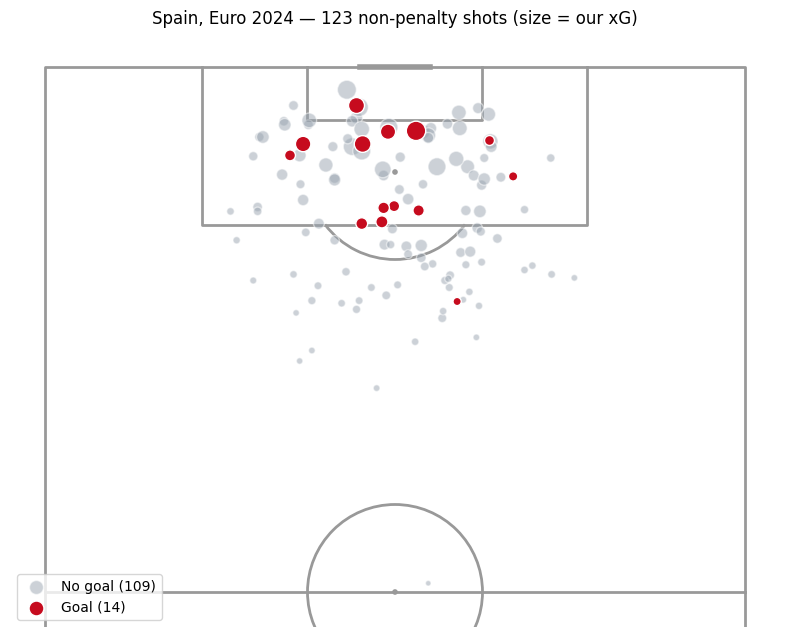

Spain xG per shot: 0.081 | tournament average: 0.086
Big chances (xG ≥ 0.20): 9


In [ ]:
spain_shots = scored[scored["match_id"].isin(team_matches["match_id"]) & (scored["team"] == TEAM)]
misses, goals = spain_shots[spain_shots["goal"] == 0], spain_shots[spain_shots["goal"] == 1]

pitch = VerticalPitch(pitch_type="statsbomb", half=True, pitch_color="white", line_color="#999999")
fig, ax = pitch.draw(figsize=(8, 7))
pitch.scatter(misses["x"], misses["y"], s=misses["p_model"] * 600 + 15, color="#9aa5b1",
              alpha=0.5, edgecolors="white", ax=ax, label=f"No goal ({len(misses)})")
pitch.scatter(goals["x"], goals["y"], s=goals["p_model"] * 600 + 15, color="#c60b1e",
              edgecolors="white", ax=ax, label=f"Goal ({len(goals)})")
ax.legend(loc="lower left")
ax.set_title(f"Spain, Euro 2024 — {len(spain_shots)} non-penalty shots (size = our xG)")
fig.savefig(FIG_DIR / "spain_shot_map.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Spain xG per shot: {spain_shots['p_model'].mean():.3f} | "
      f"tournament average: {scored['p_model'].mean():.3f}")
print("Big chances (xG ≥ 0.20):", (spain_shots["p_model"] >= 0.20).sum())

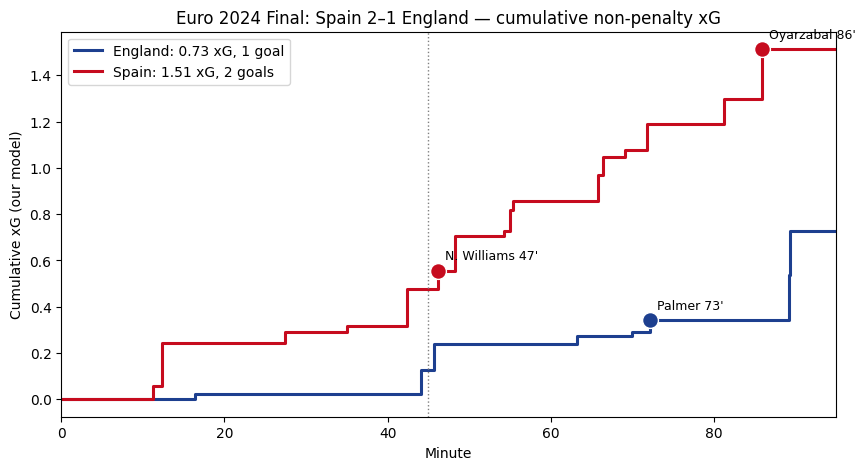

,shots,xG,statsbomb_xG,goals
team,,,,
England,9,0.73,0.73,1
Spain,16,1.51,1.79,2


In [ ]:
final_id = team_matches.loc[team_matches["stage"] == "Final", "match_id"].iloc[0]
final = scored[scored["match_id"] == final_id].sort_values(["period", "minute", "second"]).copy()
final["time"] = final["minute"] + final["second"] / 60
final["cum_xG"] = final.groupby("team")["p_model"].cumsum()

SHORT_NAMES = {"Nicholas Williams Arthuer": "N. Williams",
               "Mikel Oyarzabal Ugarte": "Oyarzabal", "Cole Palmer": "Palmer"}
COLOURS = {"Spain": "#c60b1e", "England": "#1d3f8f"}

fig, ax = plt.subplots(figsize=(10, 5))
for team, g in final.groupby("team"):
    times = [0] + g["time"].tolist() + [95]
    totals = [0] + g["cum_xG"].tolist() + [g["cum_xG"].iloc[-1]]
    n_goals = int(g["goal"].sum())
    ax.step(times, totals, where="post", color=COLOURS[team], linewidth=2.2,
            label=f"{team}: {g['p_model'].sum():.2f} xG, {n_goals} goal{'s' if n_goals != 1 else ''}")
    for _, shot in g[g["goal"] == 1].iterrows():
        ax.scatter(shot["time"], shot["cum_xG"], s=130, color=COLOURS[team],
                   edgecolor="white", zorder=3)
        name = SHORT_NAMES.get(shot["player"], shot["player"].split()[-1])
        ax.annotate(f"{name} {shot['minute'] + 1}'", (shot["time"], shot["cum_xG"]),
                    xytext=(5, 8), textcoords="offset points", fontsize=9)

ax.axvline(45, color="grey", linestyle=":", linewidth=1)
ax.set(xlabel="Minute", ylabel="Cumulative xG (our model)", xlim=(0, 95),
       title="Euro 2024 Final: Spain 2–1 England — cumulative non-penalty xG")
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "final_xg_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

final.groupby("team").agg(shots=("goal", "size"), xG=("p_model", "sum"),
                          statsbomb_xG=("statsbomb_xg", "sum"), goals=("goal", "sum")).round(2)

### 10.5 Spain at Euro 2024

These findings use the core model's non-penalty shot predictions.

**Chance creation**
- Spain recorded 123 non-penalty shots across seven matches.
- The core model assigned approximately 9.94 xG in total:
  1.42 per match and 0.081 per shot.
- Tournament-wide mean predicted xG per shot was approximately 0.086.
- Spain conceded approximately 6.24 non-penalty xG.
- Spain ranked third on core-model xG difference per match.

These comparisons describe recorded shot opportunities. They do not
directly measure possession control or explain why Spain won the tournament.
Per-match comparisons are not adjusted for opponent strength or extra time.

**Goals relative to model predictions**
- Spain scored 14 non-penalty goals from recorded shots, compared with 9.94 xG.
- Opponents scored three such goals, compared with 6.24 xG.
- Over seven matches, these differences cannot reliably separate finishing
  skill, goalkeeping, model error and chance variation.

**The final**
- Spain generated 1.51 non-penalty xG from 16 shots.
- England generated 0.73 from nine shots.
- StatsBomb's corresponding totals were 1.79 and 0.73.
- Both models therefore assigned Spain the higher total chance quality.
- The cumulative chart shows when recorded shot opportunities accumulated;
  it is not a direct measure of pressure or match control.

**Data notes**
- Penalties and shootouts are excluded.
- Own goals are excluded from shot-goal counts, so these differ from
  official match scores.
- Spain's win over Italy and Georgia's goal against Spain involved own goals.
- The core model does not include goalkeeper or defender positions.
- The xG ≥ 0.20 category is a project-defined threshold, not an official
  provider definition of a big chance.

## 11. Limitations and Conclusions

### 11.1 Main result

The project estimates non-penalty shot scoring probabilities using
shot location and recorded context.

The core logistic regression was trained on 4,302 shots from World Cup 2018,
Euro 2020 and World Cup 2022.

On 1,304 Euro 2024 shots, it achieved:
- Log loss: 0.2401, compared with 0.2692 for the training-rate baseline.
- Brier score: 0.0651.
- ROC-AUC: 0.740.

This represents approximately 10.8% lower log loss than the baseline
on this evaluation dataset.

Euro 2024 was excluded from core-model fitting and tuning.
Descriptive outcomes were inspected during initial quality checks.

### 11.2 What the analysis demonstrated

- Geometry improved predictions over a constant scoring-rate baseline.
- Core context features improved validation log loss over geometry alone.
- Tuned gradient boosting did not offer a clear advantage under the
  project's practical model-selection rule.
- Logistic regression provided interpretable conditional associations.
- Match-level resampling quantified uncertainty in the evaluation.
- The Spain analysis translated shot probabilities into match and
  tournament summaries.

### 11.3 Exploratory extension

Recorded goalkeeper and defender positions were investigated after
inspecting Euro 2024 errors.

The corrected results are reported in Sections 8 and 9.6.
Because feature development was informed by the evaluation dataset,
this extension requires confirmation on new data.

The freeze-frame comparison must not be presented as an independently
validated improvement.

### 11.4 Limitations

**Data and scope**
- Only four men's international tournaments are included.
- Findings may not transfer directly to club football or other competitions.
- The final evaluation contains 51 matches and 98 goals.
- Own goals and penalties are outside the prediction task.
- Source data may change unless a specific version is preserved.

**Features**
- Coordinates represent a standardised pitch, not measured stadium geometry.
- Freeze frames contain recorded visible players rather than complete tracking.
- Missing player coverage can affect defender counts and distances.
- Shots on the goal line use an explicit zero-area triangle convention.
- Absence of some event flags is interpreted as False during extraction.
- Several potentially useful inputs, including detailed build-up information,
  are not included.

**Evaluation**
- Some descriptive test outcomes were inspected before model evaluation.
- Some model results were seen before selection rules were recorded.
- The one-SE selection rule is a heuristic, not a formal significance test.
- Bootstrap intervals are conditional on the fitted models and observed
  tournament; they do not represent all sources of uncertainty.
- Repeated appearances by the same teams create dependence beyond individual
  matches.
- StatsBomb xG is a reference with an unknown training history relative to
  this evaluation data.

**Interpretation**
- Coefficients describe conditional associations, not causal effects.
- Correlated features complicate individual coefficient interpretation.
- Similar aggregate prediction errors do not identify their underlying cause.
- Goals minus xG over seven matches does not establish finishing ability.
- Shot-based xG does not directly measure possession control, tactical quality
  or whether a team deserved to win.

### 11.5 Next steps

1. Confirm the exploratory extension on genuinely new evaluation data.
2. Assess transfer between international and club competitions.
3. Investigate assist and build-up features using training data.
4. Assess calibration over time and across competitions.
5. Inspect unusual coordinates and recorded goalkeeper positions.
6. Develop opponent or player analysis with appropriate sample-size safeguards.

### Reproducibility

- Run the notebook from top to bottom in a fresh environment.
- Install required packages and retain the recorded package versions.
- Preserve the notebook with its generated outputs.
- Record the actual data download date and, where available, source commit.
- Cached files in temporary Colab storage do not persist across all sessions.
- Retain a durable copy of the data or a documented data-retrieval procedure.

Data: Hudl StatsBomb Open Data — https://github.com/statsbomb/open-data

In [ ]:
packages = ["numpy", "pandas", "scikit-learn", "matplotlib", "mplsoccer"]
requirements = "\n".join(f"{p}=={version(p)}" for p in packages)
Path("requirements.txt").write_text(requirements + "\n")
print(requirements)

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
mplsoccer==1.8.1
